In [1]:
import torch
from torch import nn, optim
from torchvision import datasets, transforms
import matplotlib.pyplot as plt
import numpy as np

In [ ]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

batch_size = 256

trainset = datasets.MNIST("./dataset/", train = True, transform = transforms.ToTensor(), download = True)
#dataloader = torch.utils.data.DataLoader(trainset, batch_size = batch_size, shuffle = True, num_workers = 2)

testset = datasets.MNIST("./dataset/", train = False, transform = transforms.ToTensor(), download =   True)
#testloader = torch.utils.data.DataLoader(testset, batch_size = batch_size, shuffle = False, num_workers = 2)

dataset = torch.utils.data.ConcatDataset([trainset, testset])
dataloader = torch.utils.data.DataLoader(
	dataset,
	batch_size = batch_size,
	shuffle = True
)

tensor_to_img = transforms.ToPILImage()

## Standarized output

### Train

In [3]:
class SAE(nn.Module):
	def __init__(self):
		super().__init__()

		self.encoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(28 * 28, 500),
			nn.ReLU(),
		)

		self.decoder_layer_1 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 28 * 28),
			nn.Sigmoid(),
		)

		self.encoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.decoder_layer_2 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 500),
			nn.ReLU(),
		)

		self.encoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(500, 2000),
			nn.ReLU(),
		)

		self.decoder_layer_3 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 500),
			nn.ReLU(),
		)

		self.encoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(2000, 10),
		)

		self.decoder_layer_4 =  nn.Sequential(
			nn.Dropout(0.2),
			nn.Linear(10, 2000),
			nn.ReLU(),
		)

	def forward(self, x):
		encoded = self.encoder_layer_4(
					self.encoder_layer_3(
						self.encoder_layer_2(
							self.encoder_layer_1(x)
						)
					)
				)

		decoded = self.decoder_layer_1(
					self.decoder_layer_2(
						self.decoder_layer_3(
							self.decoder_layer_4(encoded)
						)
					)
				)
		return decoded
	
	def encode(self, x):
		e1 = self.encoder_layer_1(x)
		e2 = self.encoder_layer_2(e1)
		e3 = self.encoder_layer_3(e2)
		z = self.encoder_layer_4(e3)
		return z

In [4]:
activation_func = "standarized"

model = SAE()
model.to(device)

# Pretraining
pretrain_epochs = 200

# Pretrain layer 1

loss_function = nn.BCELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_1.parameters()) + 
    list(model.decoder_layer_1.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
	batch_losses = []
	
	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)
		e1 = model.encoder_layer_1(images)
		e1_reconstructed = model.decoder_layer_1(e1)
		loss = loss_function(e1_reconstructed, images)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 1: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre1")

		print(f"Best Pretrain 1 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")

# Pretrain layer 2

model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_2.parameters()) + 
    list(model.decoder_layer_2.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()

for epoch in range(pretrain_epochs):
	batch_losses = []

	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)

		with torch.no_grad():
			e1 = model.encoder_layer_1(images)
		
		e2 = model.encoder_layer_2(e1)
		e1_reconstructed = model.decoder_layer_2(e2)

		loss = loss_function(e1_reconstructed, e1)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 2: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre2")

		print(f"Best Pretrain 2 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 3

model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_3.parameters()) + 
    list(model.decoder_layer_3.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()

for epoch in range(pretrain_epochs):
	batch_losses = []

	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)

		with torch.no_grad():
			e1 = model.encoder_layer_1(images)
			e2 = model.encoder_layer_2(e1)
		
		e3 = model.encoder_layer_3(e2)
		e2_reconstructed = model.decoder_layer_3(e3)

		loss = loss_function(e2_reconstructed, e2)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 3: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre3")

		print(f"Best Pretrain 3 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


# Pretrain layer 4

model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))

loss_function = nn.MSELoss()

optimizer = optim.SGD(
    list(model.encoder_layer_4.parameters()) + 
    list(model.decoder_layer_4.parameters()),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

# Deactivate Dropout because Layer is Frozen
model.encoder_layer_1.eval()
model.encoder_layer_2.eval()
model.encoder_layer_3.eval()

for epoch in range(pretrain_epochs):
	batch_losses = []

	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)

		with torch.no_grad():
			e1 = model.encoder_layer_1(images)
			e2 = model.encoder_layer_2(e1)
			e3 = model.encoder_layer_3(e2)
		
		e4 = model.encoder_layer_4(e3)
		e3_reconstructed = model.decoder_layer_4(e4)

		loss = loss_function(e3_reconstructed, e3)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Pretrain 4: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/pre4")

		print(f"Best Pretrain 4 Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")
		


Pretrain 1: Epoch 1/200, Loss: 0.340903
Best Pretrain 1 Epoch: 1/200, Loss: 0.340903
Pretrain 1: Epoch 2/200, Loss: 0.243975
Best Pretrain 1 Epoch: 2/200, Loss: 0.243975
Pretrain 1: Epoch 3/200, Loss: 0.214102
Best Pretrain 1 Epoch: 3/200, Loss: 0.214102
Pretrain 1: Epoch 4/200, Loss: 0.195584
Best Pretrain 1 Epoch: 4/200, Loss: 0.195584
Pretrain 1: Epoch 5/200, Loss: 0.183012
Best Pretrain 1 Epoch: 5/200, Loss: 0.183012
Pretrain 1: Epoch 6/200, Loss: 0.173700
Best Pretrain 1 Epoch: 6/200, Loss: 0.173700
Pretrain 1: Epoch 7/200, Loss: 0.166315
Best Pretrain 1 Epoch: 7/200, Loss: 0.166315
Pretrain 1: Epoch 8/200, Loss: 0.160192
Best Pretrain 1 Epoch: 8/200, Loss: 0.160192
Pretrain 1: Epoch 9/200, Loss: 0.154960
Best Pretrain 1 Epoch: 9/200, Loss: 0.154960
Pretrain 1: Epoch 10/200, Loss: 0.150463
Best Pretrain 1 Epoch: 10/200, Loss: 0.150463
Pretrain 1: Epoch 11/200, Loss: 0.146521
Best Pretrain 1 Epoch: 11/200, Loss: 0.146521
Pretrain 1: Epoch 12/200, Loss: 0.142961
Best Pretrain 1 Epoc

In [5]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))

train_epochs = 400

loss_function = nn.BCELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr = 0.1, 
    momentum = 0.9
    )

scheduler = optim.lr_scheduler.StepLR(
	optimizer, 
	step_size = 20000, #Amount of iterations the scheduler will update the lr
	gamma = 0.5 #by how much the scheduler will divide the current lr
	)

best_loss = (float("inf"), 0)

model.eval() # deactivate all dropout
for epoch in range(train_epochs):
	batch_losses = []
	
	for images, _ in dataloader:

		images = torch.flatten(images, start_dim = 1).to(device)
		reconstructed = model(images)
		loss = loss_function(reconstructed, images)

		optimizer.zero_grad()
		loss.backward()
		optimizer.step()

		scheduler.step()

		batch_losses.append(loss.item())
	
	epoch_loss = sum(batch_losses) / len(batch_losses)

	print(f"Finetune: Epoch {epoch+1}/{train_epochs}, Loss: {epoch_loss:.6f}")

	if epoch_loss <= best_loss[0]:
		best_loss = (epoch_loss, epoch + 1)
		torch.save(model.state_dict(), "./models/" + activation_func + "/finetuned")

		print(f"Best Finetune Epoch: {best_loss[1]}/{train_epochs}, Loss: {best_loss[0]:.6f}")

Finetune: Epoch 1/400, Loss: 0.145149
Best Finetune Epoch: 1/400, Loss: 0.145149
Finetune: Epoch 2/400, Loss: 0.125308
Best Finetune Epoch: 2/400, Loss: 0.125308
Finetune: Epoch 3/400, Loss: 0.120016
Best Finetune Epoch: 3/400, Loss: 0.120016
Finetune: Epoch 4/400, Loss: 0.116840
Best Finetune Epoch: 4/400, Loss: 0.116840
Finetune: Epoch 5/400, Loss: 0.114559
Best Finetune Epoch: 5/400, Loss: 0.114559
Finetune: Epoch 6/400, Loss: 0.112801
Best Finetune Epoch: 6/400, Loss: 0.112801
Finetune: Epoch 7/400, Loss: 0.111343
Best Finetune Epoch: 7/400, Loss: 0.111343
Finetune: Epoch 8/400, Loss: 0.110115
Best Finetune Epoch: 8/400, Loss: 0.110115
Finetune: Epoch 9/400, Loss: 0.109065
Best Finetune Epoch: 9/400, Loss: 0.109065
Finetune: Epoch 10/400, Loss: 0.108126
Best Finetune Epoch: 10/400, Loss: 0.108126
Finetune: Epoch 11/400, Loss: 0.107351
Best Finetune Epoch: 11/400, Loss: 0.107351
Finetune: Epoch 12/400, Loss: 0.106557
Best Finetune Epoch: 12/400, Loss: 0.106557
Finetune: Epoch 13/400

### Visualize

In [6]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = SAE()
model.to(device)

SAE(
  (encoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=784, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_1): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=784, bias=True)
    (2): Sigmoid()
  )
  (encoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (decoder_layer_2): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=500, out_features=2000, bias=True)
    (2): ReLU()
  )
  (decoder_layer_3): Sequential(
    (0): Dropout(p=0.2, inplace=False)
    (1): Linear(in_features=2000, out_features=500, bias=True)
    (2): ReLU()
  )
  (encoder_layer_4): Sequential(
    (0): Dropout(p=0.2, inplace=F

#### Autoencoder Layer 1


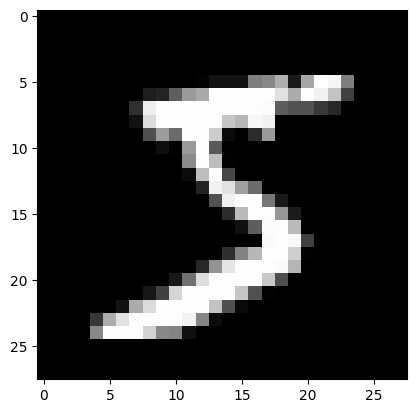

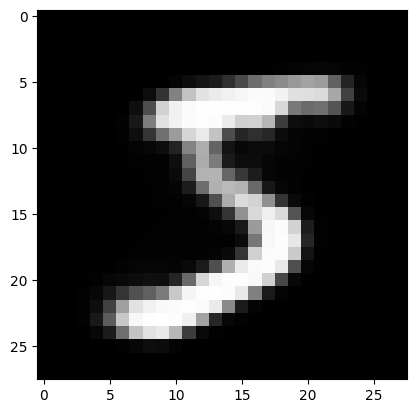

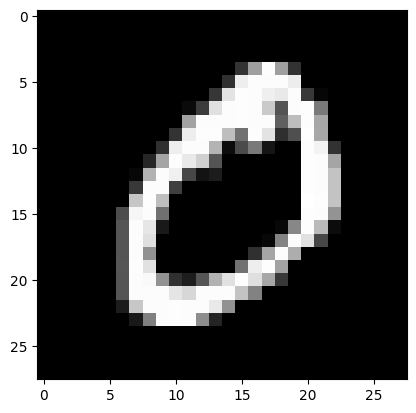

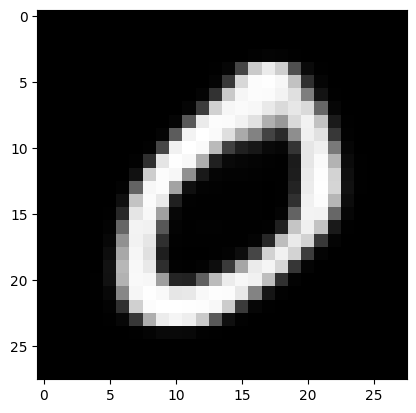

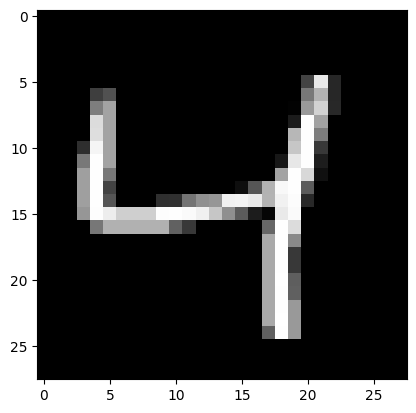

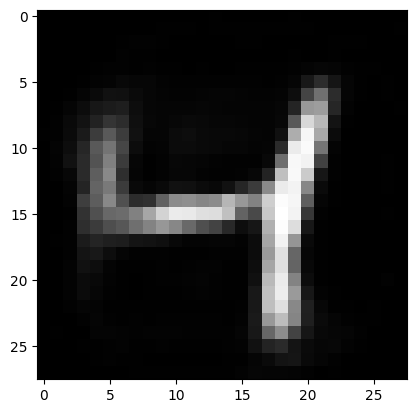

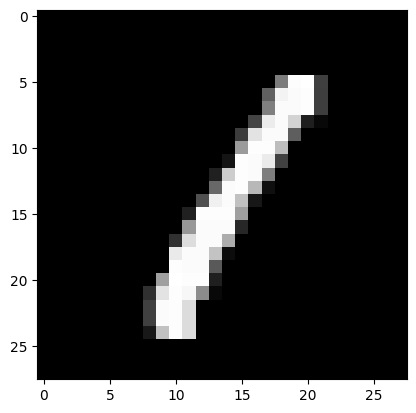

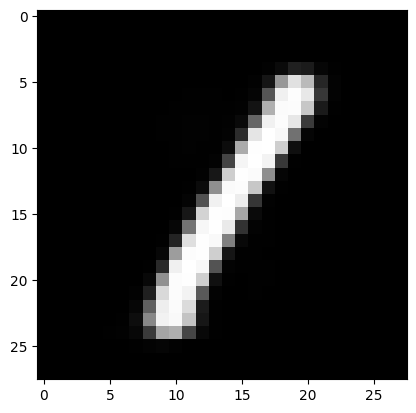

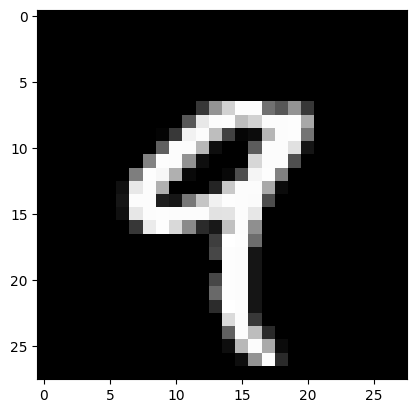

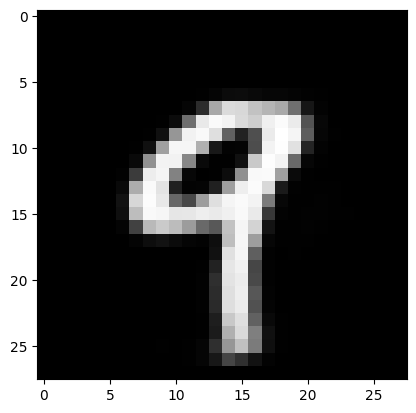

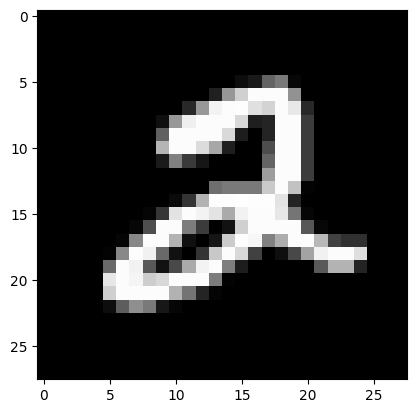

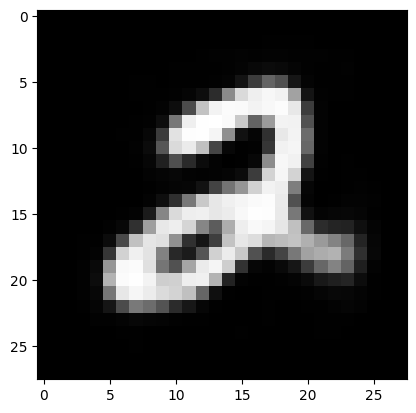

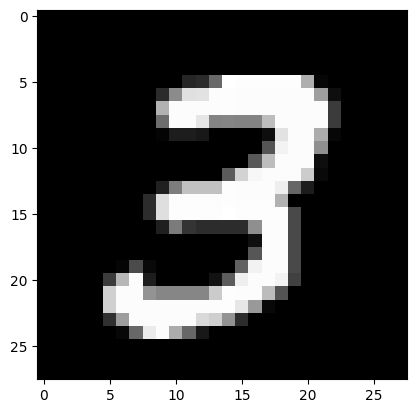

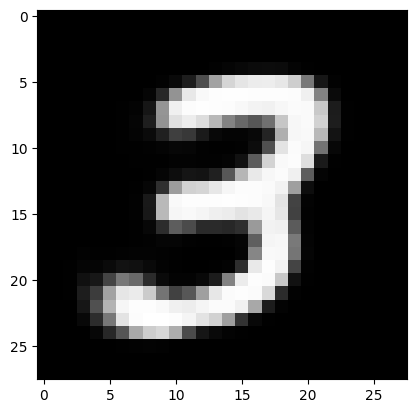

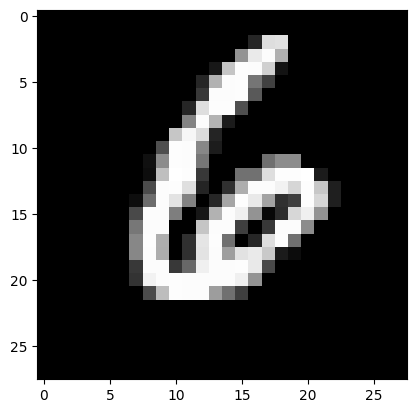

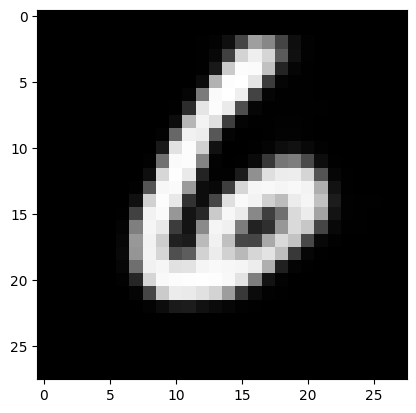

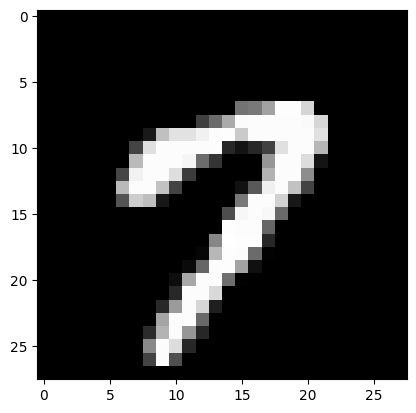

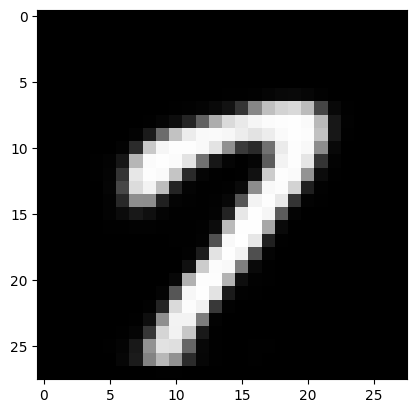

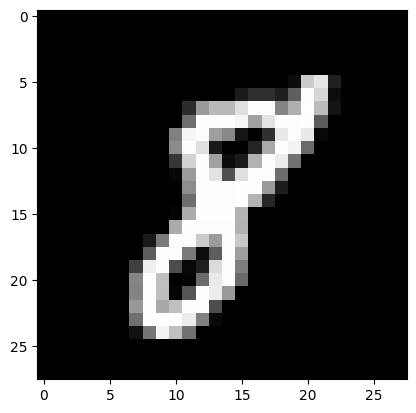

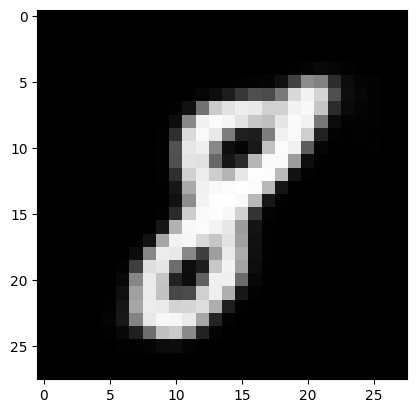

In [7]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre1", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e1_reconstructed = model.decoder_layer_1(e1)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	# To view it:
	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 2


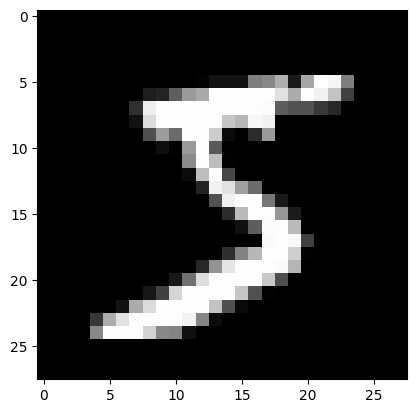

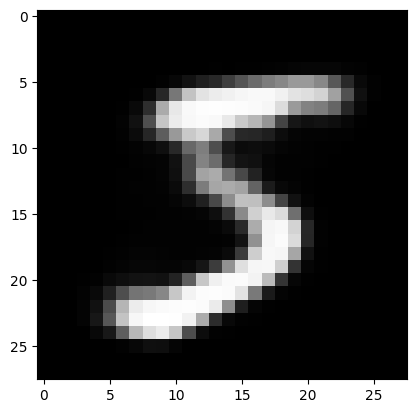

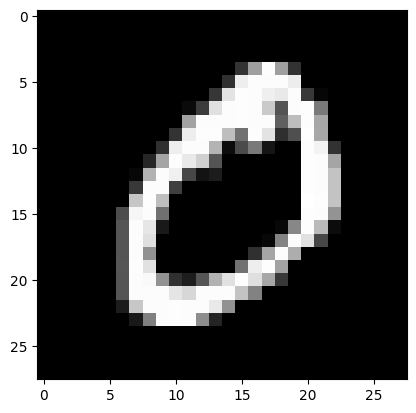

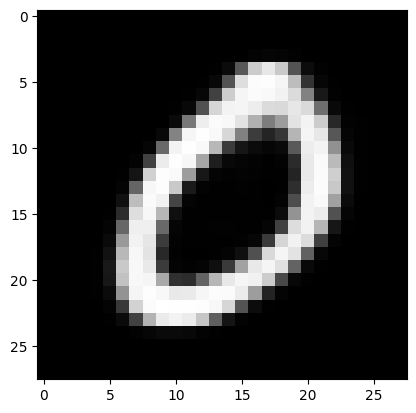

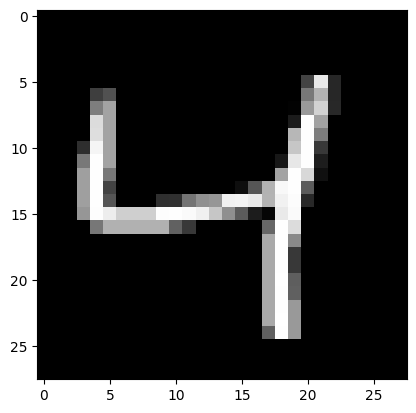

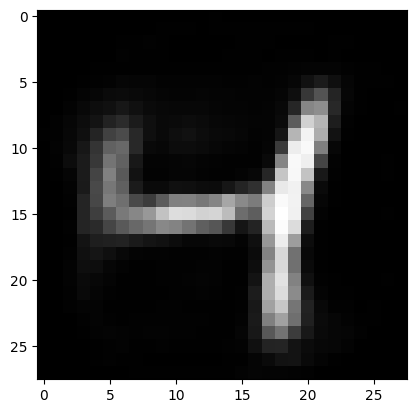

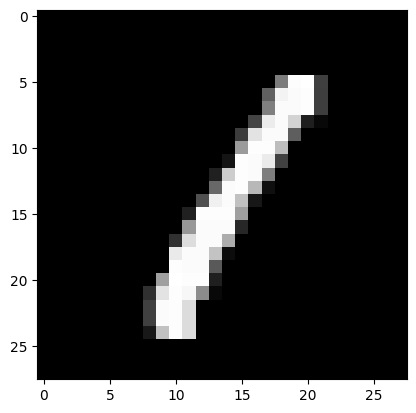

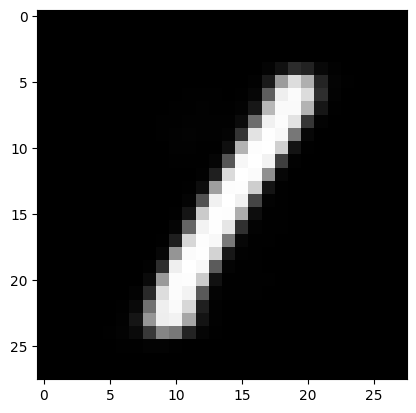

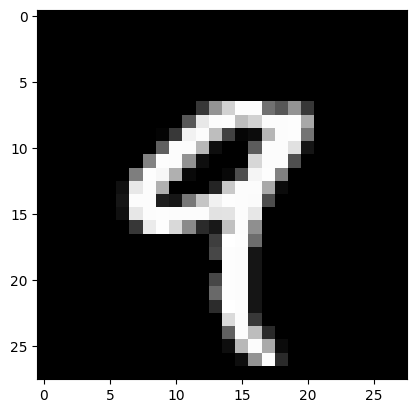

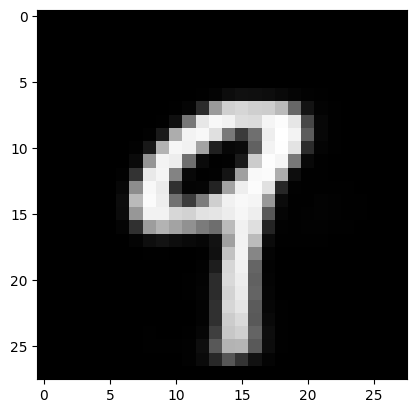

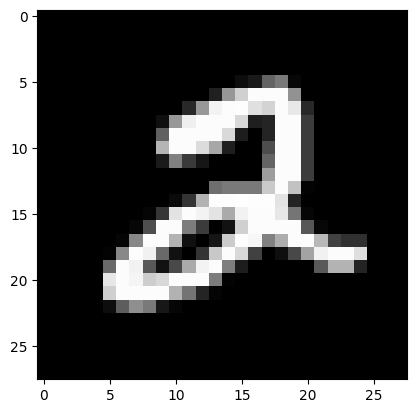

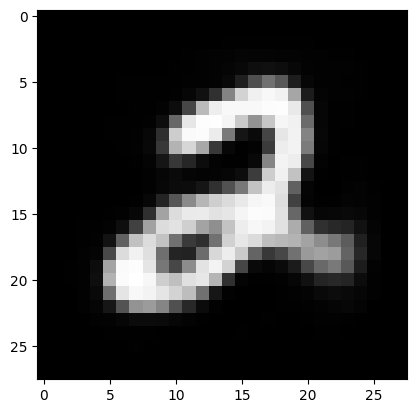

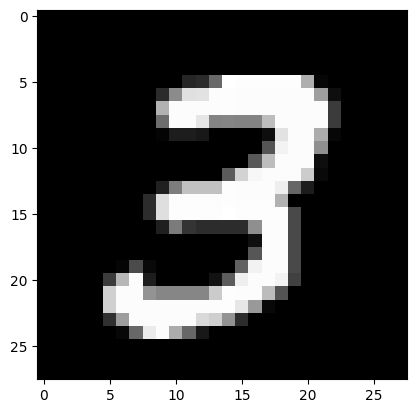

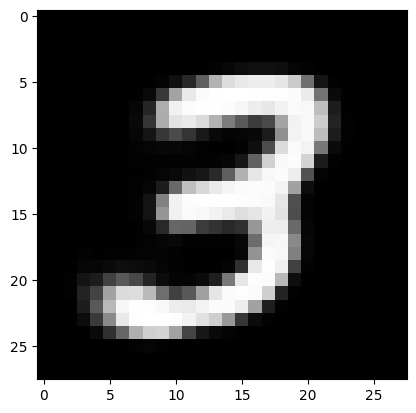

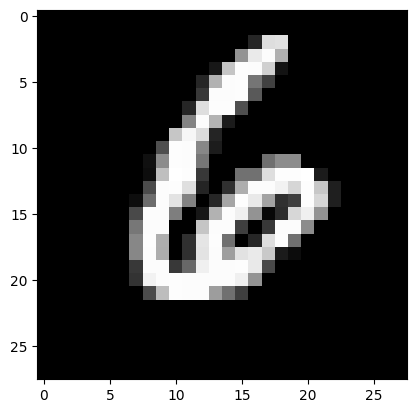

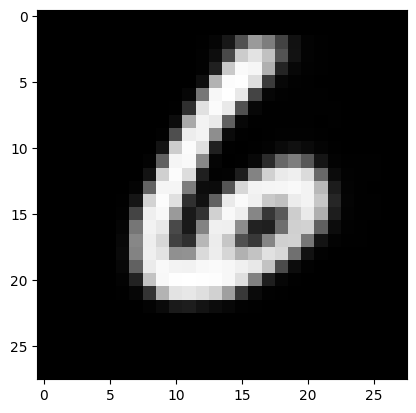

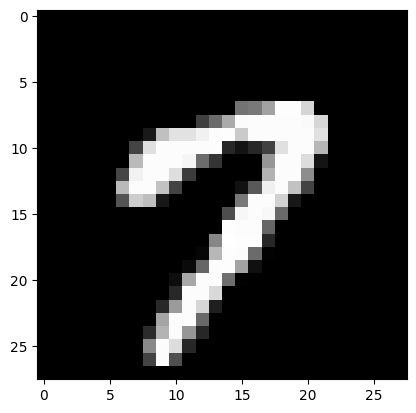

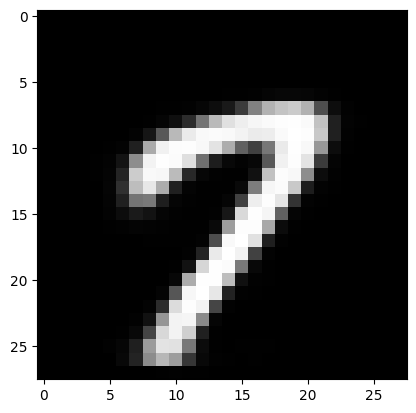

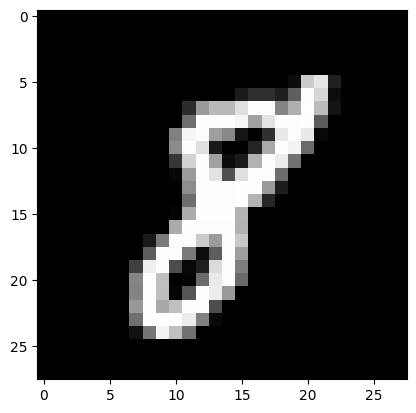

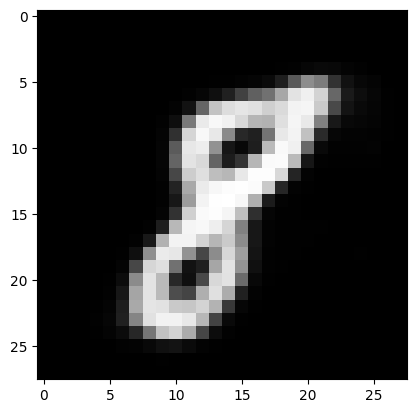

In [8]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre2", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)

		e2_reconstructed = model.decoder_layer_2(e2)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 3


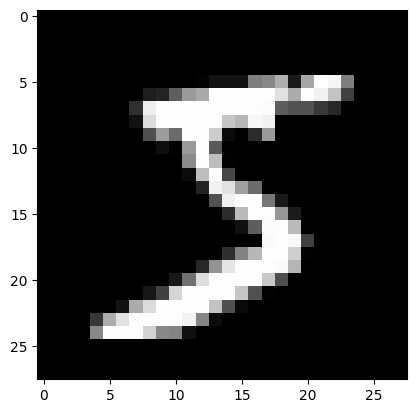

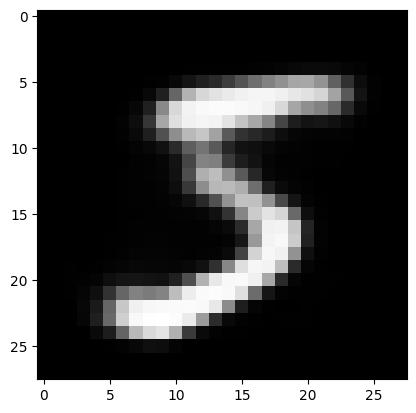

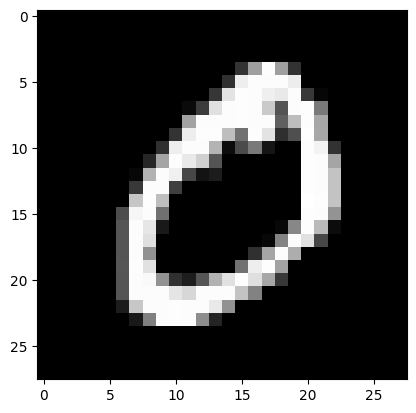

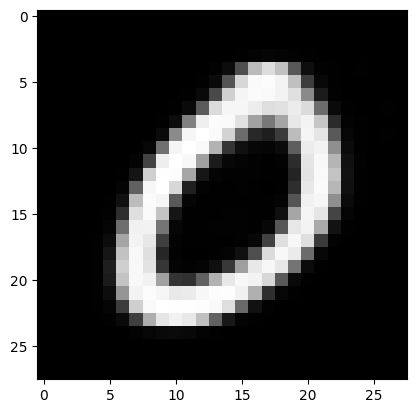

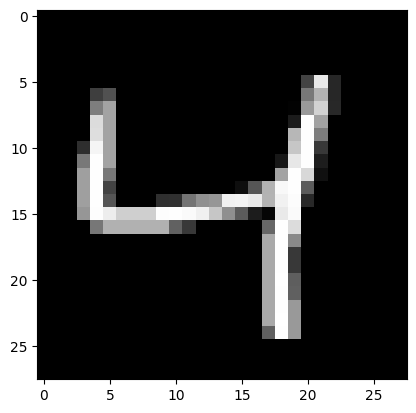

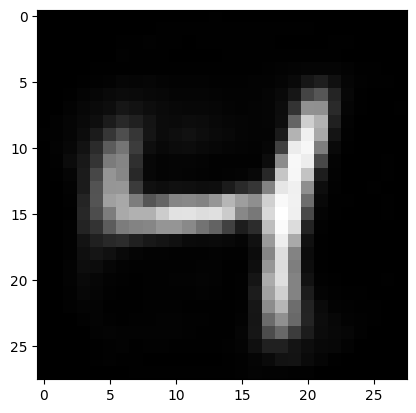

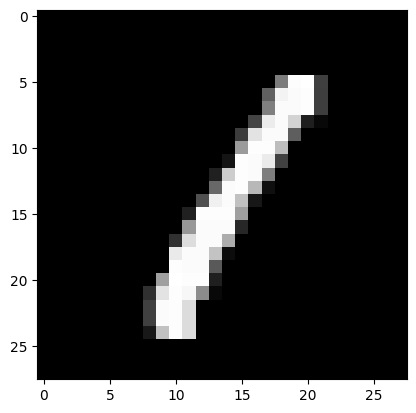

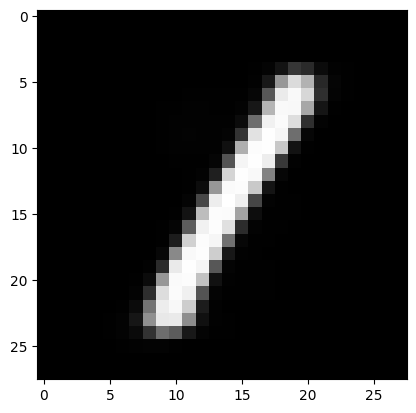

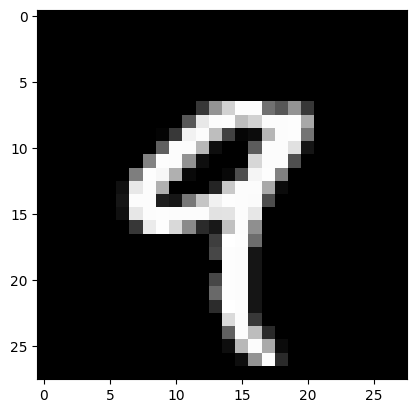

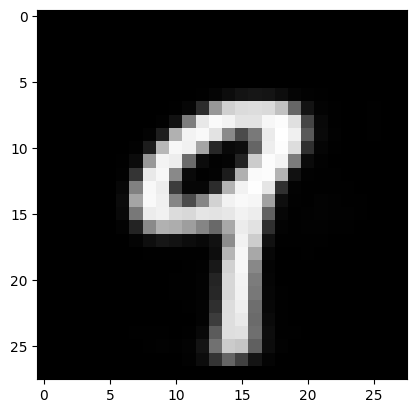

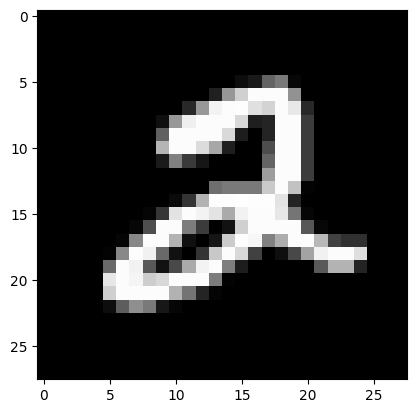

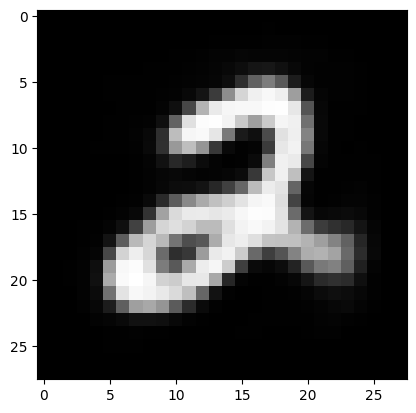

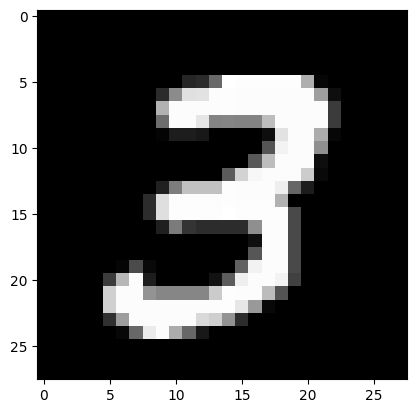

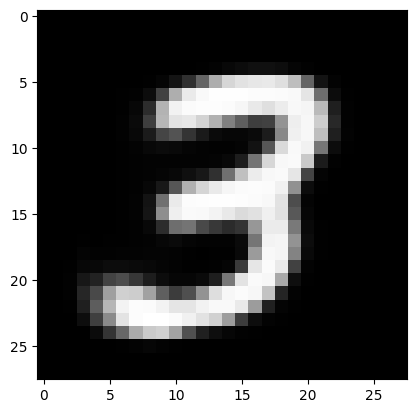

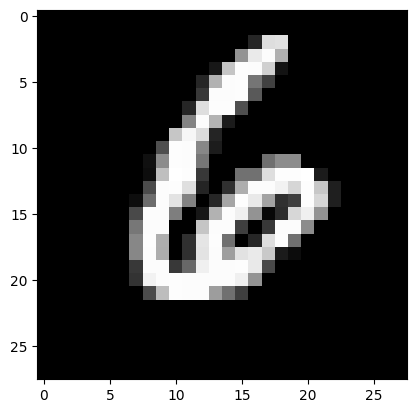

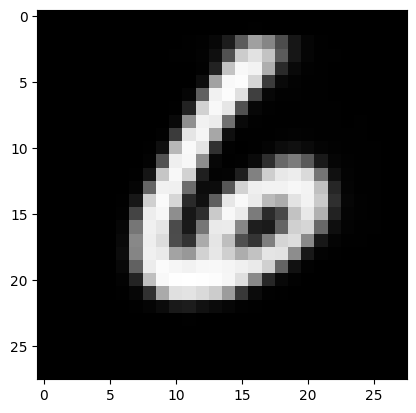

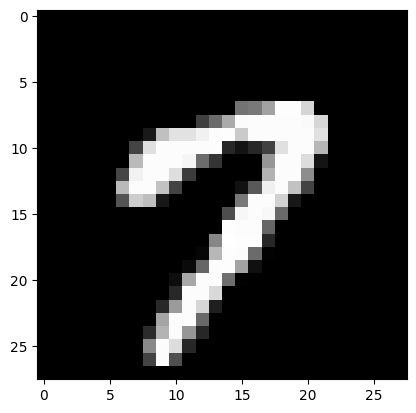

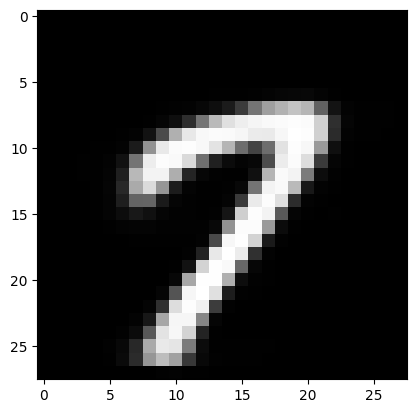

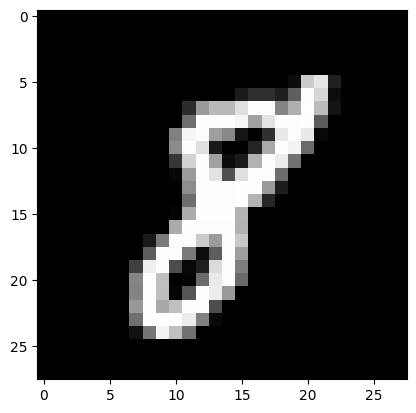

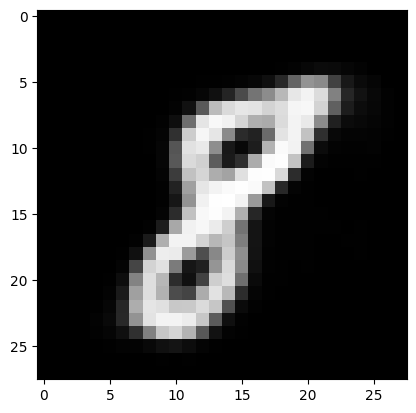

In [9]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre3", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)

		e3_reconstructed = model.decoder_layer_3(e3)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Autoencoder Layer 4


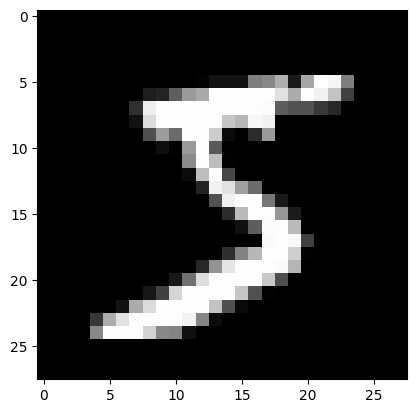

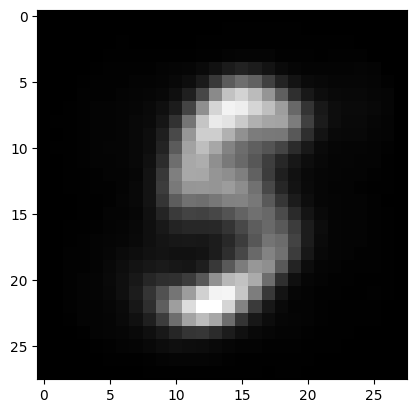

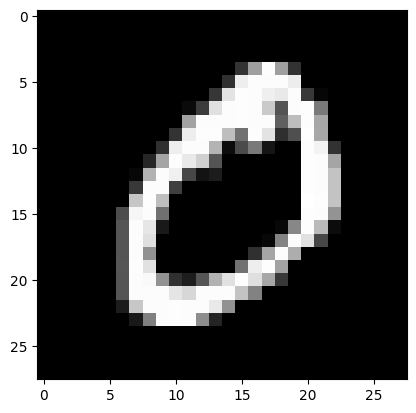

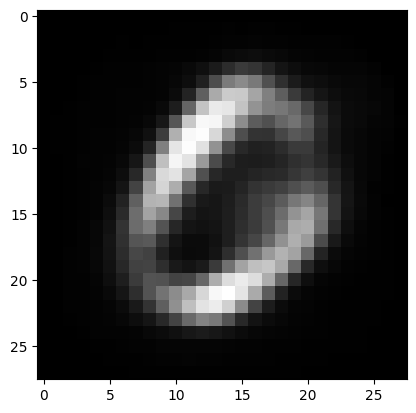

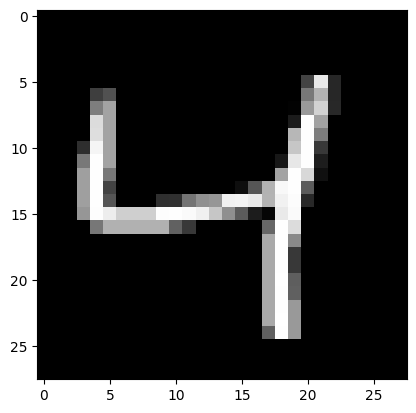

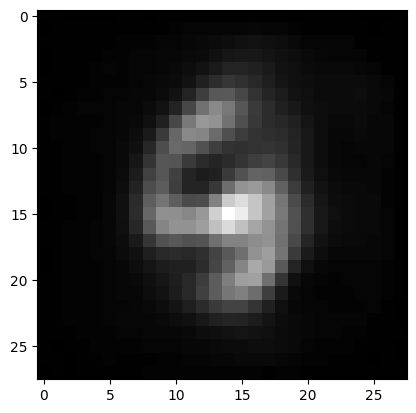

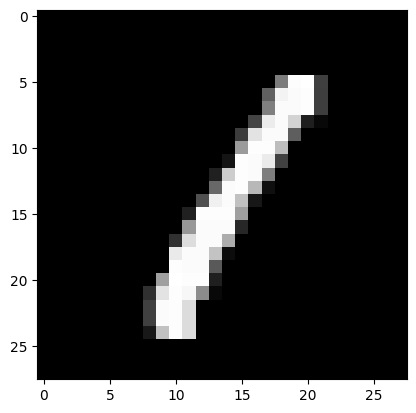

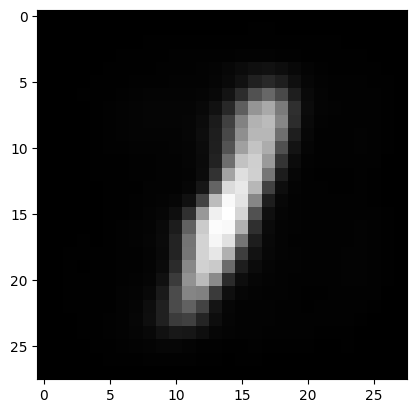

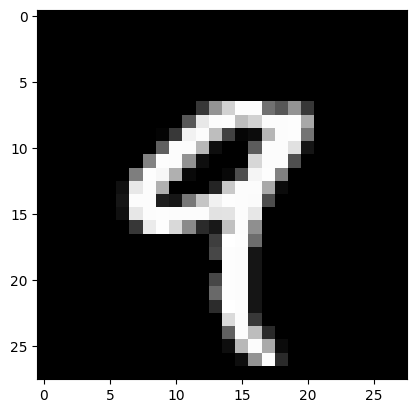

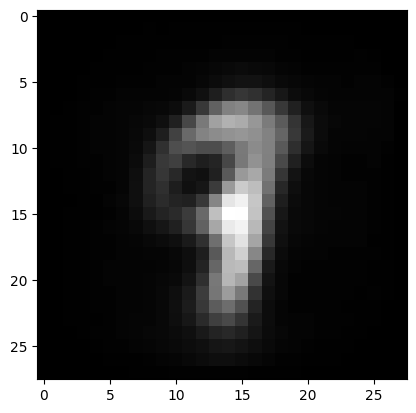

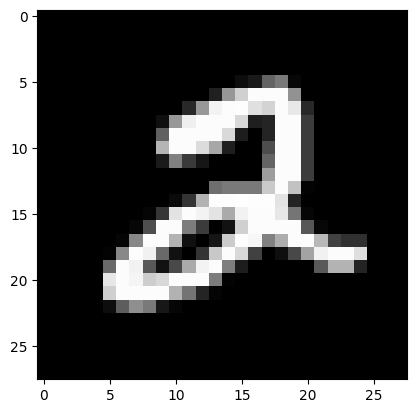

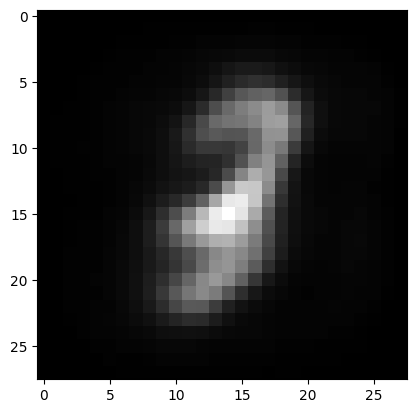

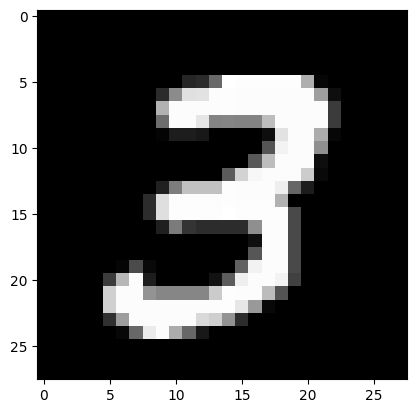

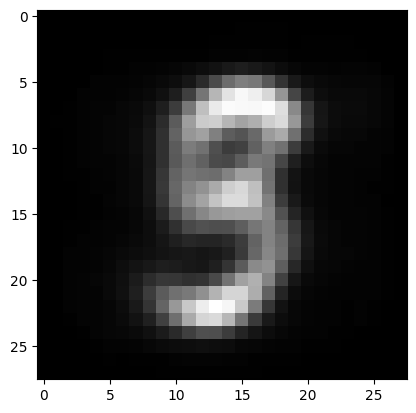

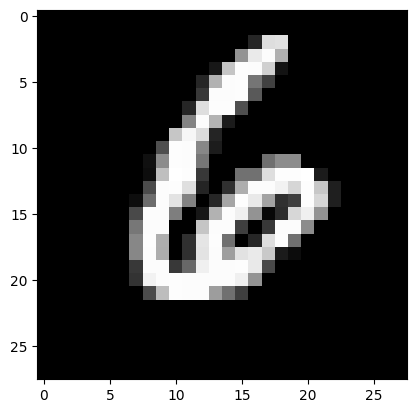

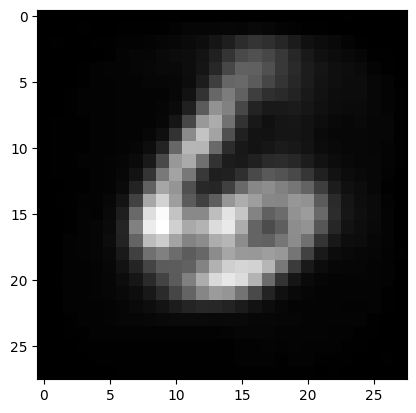

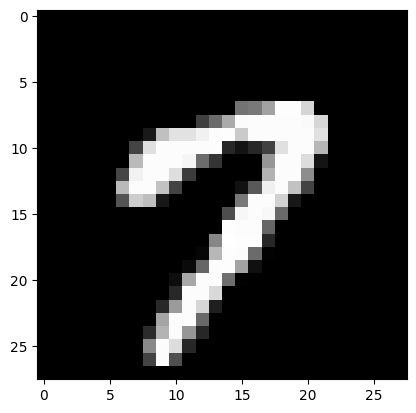

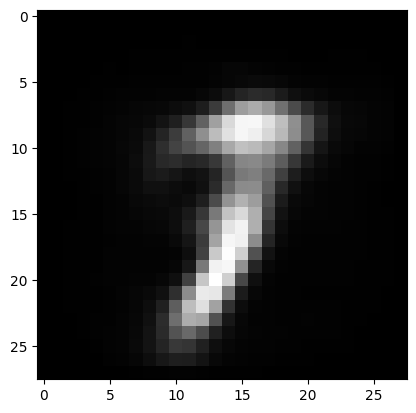

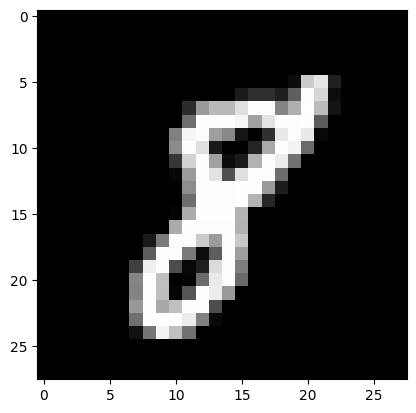

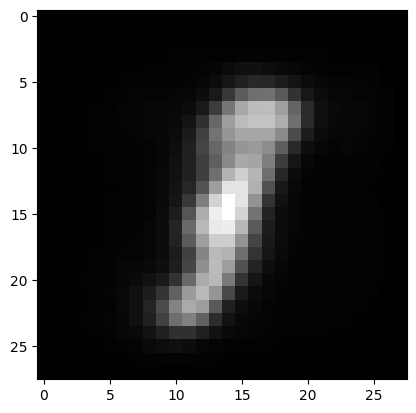

In [10]:
model.load_state_dict(torch.load("./models/" + activation_func + "/pre4", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)

		e1 = model.encoder_layer_1(image_tensor)
		e2 = model.encoder_layer_2(e1)
		e3 = model.encoder_layer_3(e2)
		e4 = model.encoder_layer_4(e3)

		e4_reconstructed = model.decoder_layer_4(e4)
		e3_reconstructed = model.decoder_layer_3(e4_reconstructed)
		e2_reconstructed = model.decoder_layer_2(e3_reconstructed)
		e1_reconstructed = model.decoder_layer_1(e2_reconstructed)

	e1_reconstructed = torch.unflatten(e1_reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(e1_reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

#### Finetuned

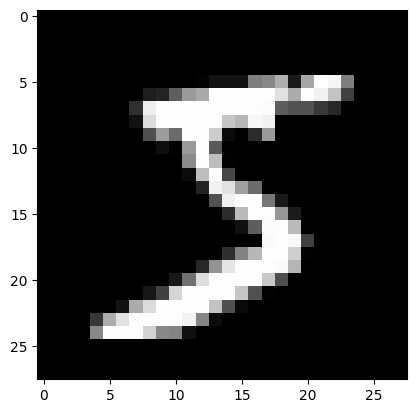

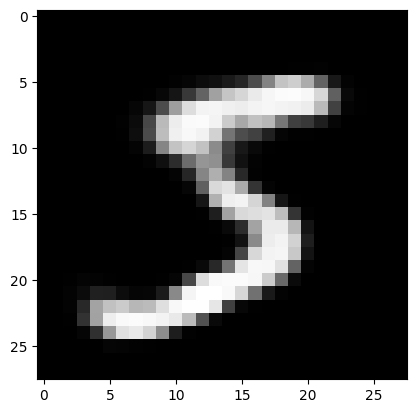

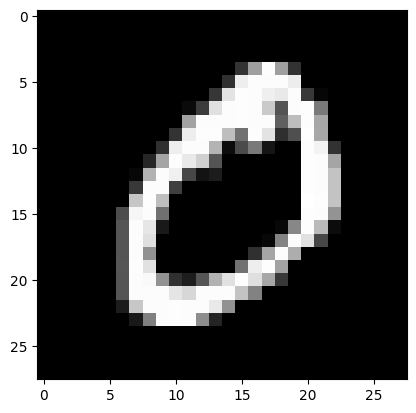

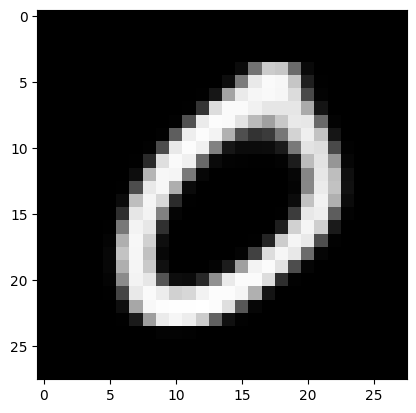

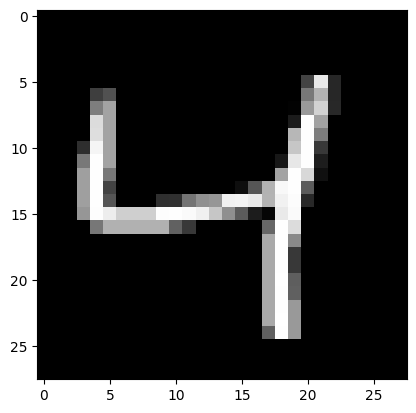

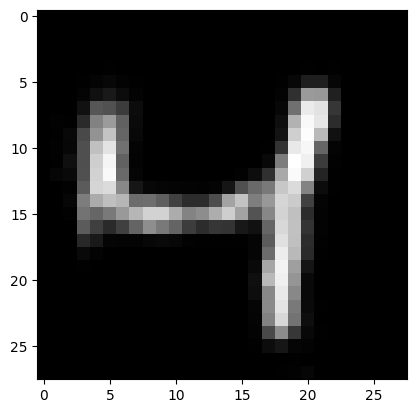

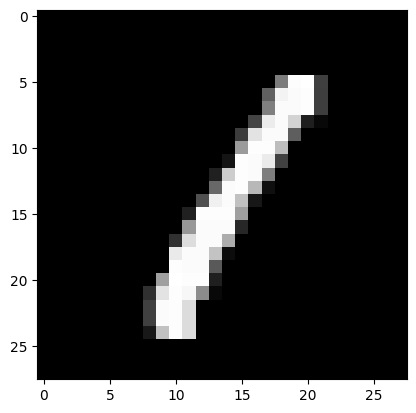

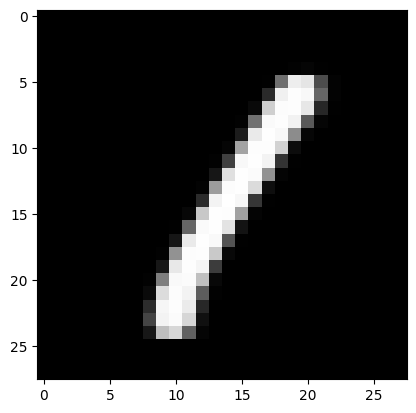

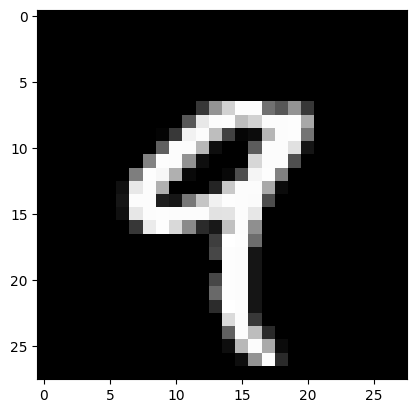

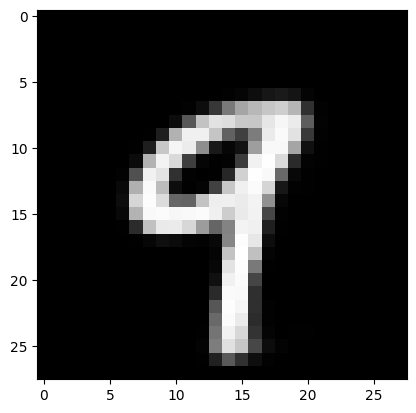

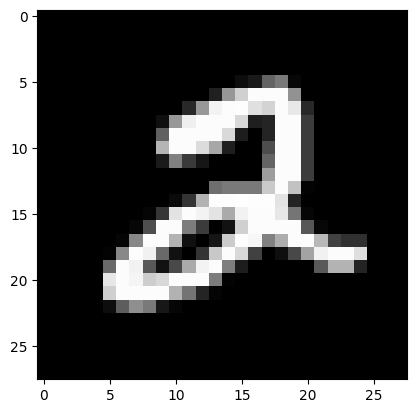

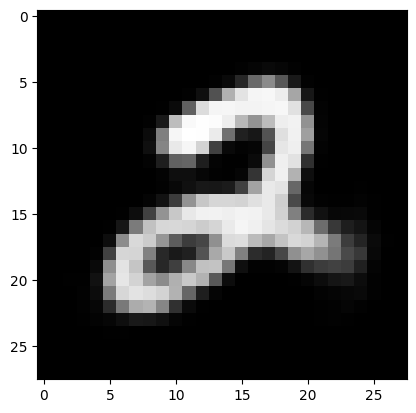

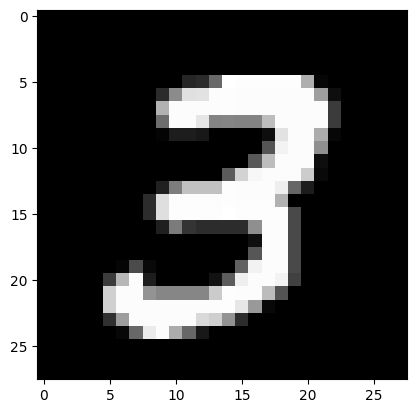

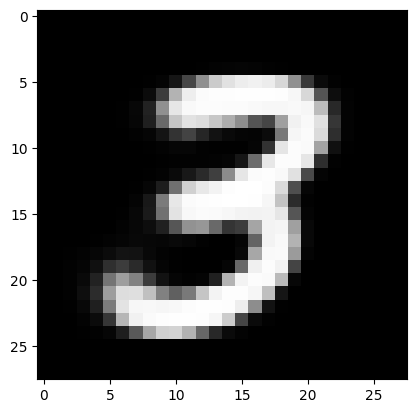

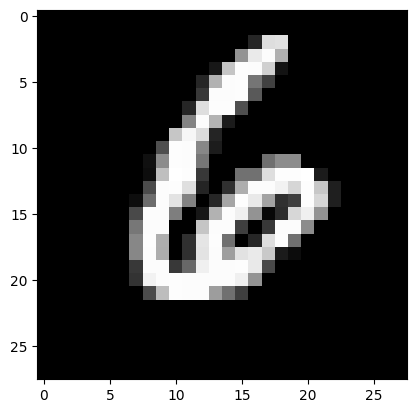

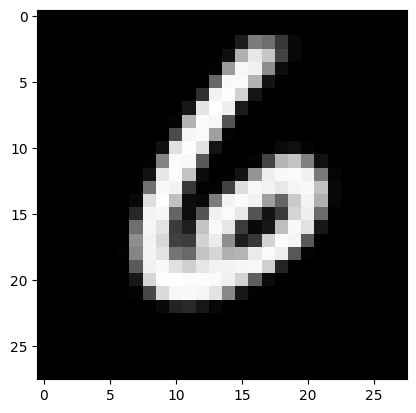

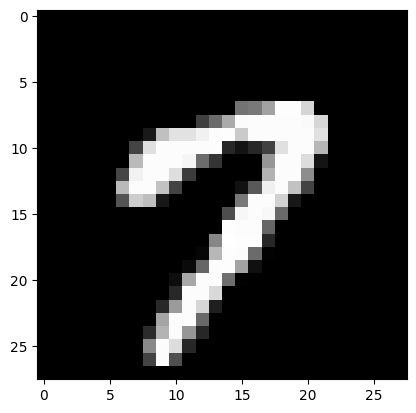

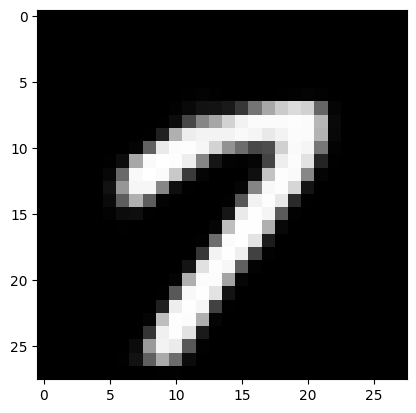

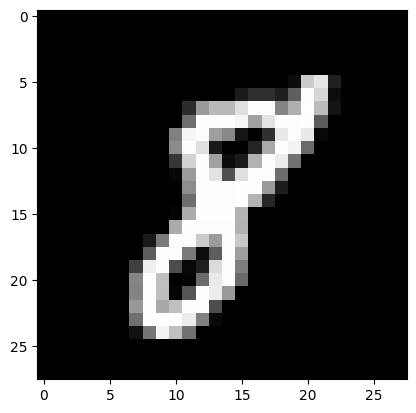

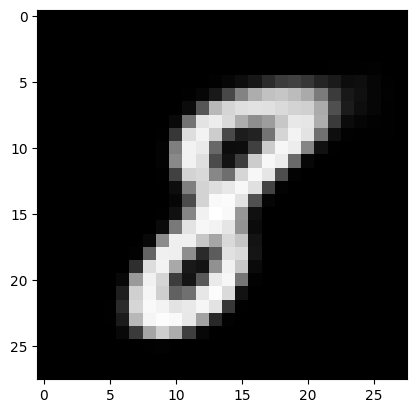

In [11]:
model.load_state_dict(torch.load("./models/" + activation_func + "/finetuned", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = torch.flatten(image_tensor).to(device)
		reconstructed = model(image_tensor)

	reconstructed = torch.unflatten(reconstructed, dim = 0, sizes = (28, 28)).to(device)

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [12]:
model = SAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "/finetuned", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = torch.flatten(images, start_dim = 1).to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [13]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

scaler = StandardScaler()
Z = scaler.fit_transform(Z)

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [14]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6781
NMI: 0.7341


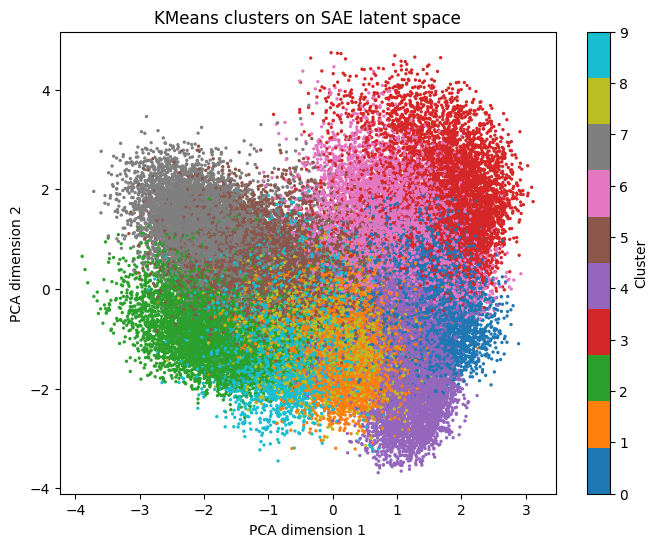

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

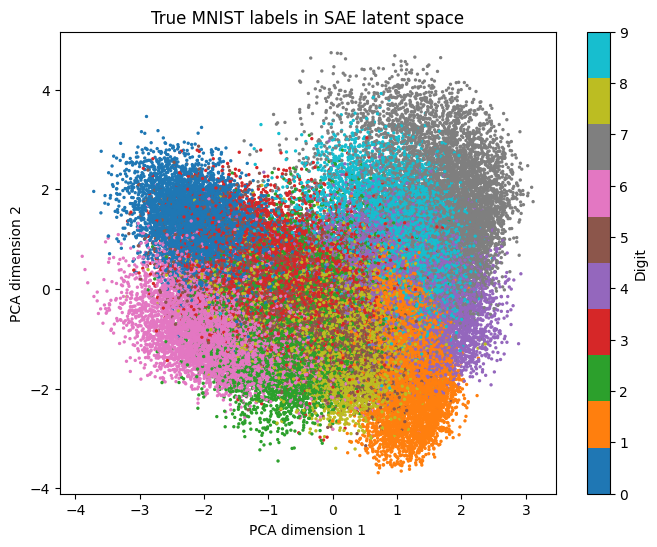

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [17]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


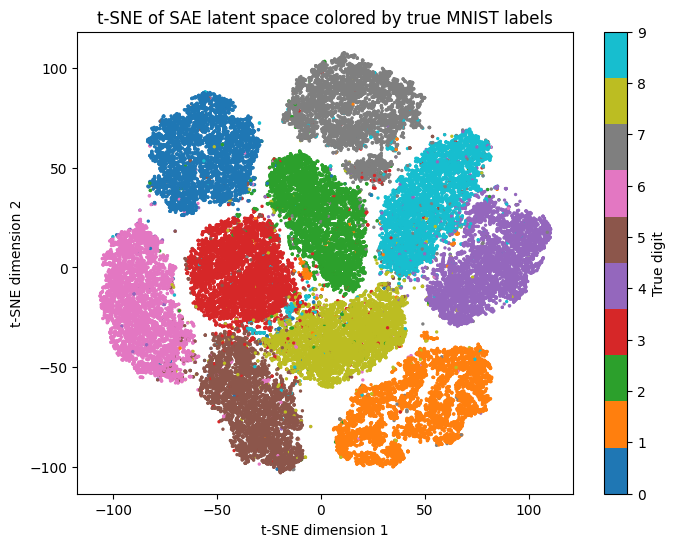

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

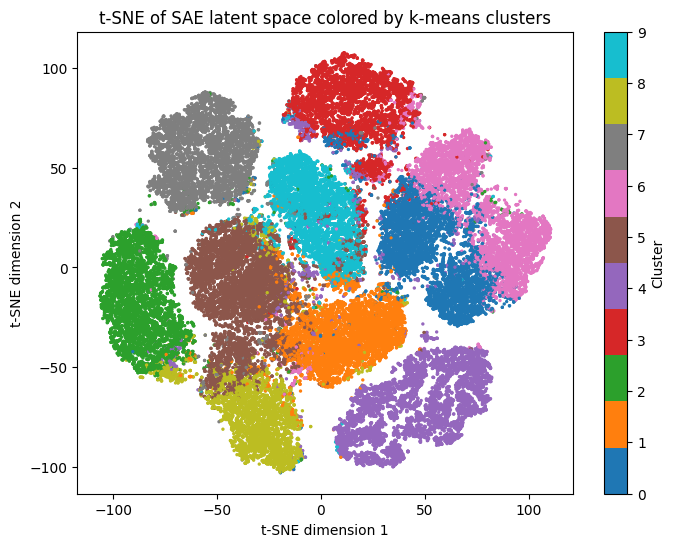

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [20]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.8015


In [21]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,30,9,19,5,3005,34,3,448,156,3521
1,25,14,356,227,3,113,41,10,5781,66
2,55,3,41,3,66,47,6312,1,31,6
3,3,1,154,51,2,1,0,5967,6,149
4,9,7726,173,86,63,34,88,416,76,77
5,17,38,376,6281,0,1552,2,10,493,119
6,1,38,21,23,3665,35,18,330,103,2944
7,6739,0,83,23,3,135,57,47,34,58
8,18,9,6,229,4,4352,341,0,118,9


In [22]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.00,0.00,0.42,0.00,0.00,0.06,0.02,0.49
1,0.00,0.00,0.05,0.03,0.00,0.02,0.01,0.00,0.87,0.01
2,0.01,0.00,0.01,0.00,0.01,0.01,0.96,0.00,0.00,0.00
3,0.00,0.00,0.02,0.01,0.00,0.00,0.00,0.94,0.00,0.02
4,0.00,0.88,0.02,0.01,0.01,0.00,0.01,0.05,0.01,0.01
5,0.00,0.00,0.04,0.71,0.00,0.17,0.00,0.00,0.06,0.01
6,0.00,0.01,0.00,0.00,0.51,0.00,0.00,0.05,0.01,0.41
7,0.94,0.00,0.01,0.00,0.00,0.02,0.01,0.01,0.00,0.01
8,0.00,0.00,0.00,0.05,0.00,0.86,0.07,0.00,0.02,0.00


## Convolutional No MaxPol - Standarized

### Train

In [ ]:
import torch
import torch.nn as nn

class ConvSAE(nn.Module):
    def __init__(self, latent_dim = 10):
        super().__init__()

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(
                1, 32, 
                kernel_size = 3,
                stride = 2,
                padding = 1
            ),  # 28 -> 14
            nn.ReLU(),

            nn.Conv2d(
                32, 64, 
                kernel_size = 3, 
                stride = 2, 
                padding = 1
            ), # 14 -> 7
            nn.ReLU(),
        )

        self.encoder_fc = nn.Linear(64 * 7 * 7, latent_dim)

        self.decoder_fc = nn.Linear(latent_dim, 64 * 7 * 7)

        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(
                64, 32,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),  # 7 -> 14
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 1,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),  # 14 -> 28
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder_conv(x)
        h = h.view(h.size(0), -1)
        z = self.encoder_fc(h)
        return z

    def decode(self, z):
        h = self.decoder_fc(z)
        h = h.view(z.size(0), 64, 7, 7)
        x_hat = self.decoder_conv(h)
        return x_hat

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

In [26]:
activation_func = "Convolution"
model = ConvSAE()
model.to(device)

pretrain_epochs = 400

loss_function = nn.BCELoss()

optimizer = optim.AdamW(
	model.parameters(),
	lr = 1e-3,
	weight_decay = 1e-4
	)

"""scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )"""

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = images.to(device)
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Train: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "model")

        print(f"Best Train Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


Train: Epoch 1/400, Loss: 0.224420
Best Train Epoch: 1/400, Loss: 0.224420
Train: Epoch 2/400, Loss: 0.142924
Best Train Epoch: 2/400, Loss: 0.142924
Train: Epoch 3/400, Loss: 0.131373
Best Train Epoch: 3/400, Loss: 0.131373
Train: Epoch 4/400, Loss: 0.124881
Best Train Epoch: 4/400, Loss: 0.124881
Train: Epoch 5/400, Loss: 0.120816
Best Train Epoch: 5/400, Loss: 0.120816
Train: Epoch 6/400, Loss: 0.118139
Best Train Epoch: 6/400, Loss: 0.118139
Train: Epoch 7/400, Loss: 0.116190
Best Train Epoch: 7/400, Loss: 0.116190
Train: Epoch 8/400, Loss: 0.114691
Best Train Epoch: 8/400, Loss: 0.114691
Train: Epoch 9/400, Loss: 0.113481
Best Train Epoch: 9/400, Loss: 0.113481
Train: Epoch 10/400, Loss: 0.112528
Best Train Epoch: 10/400, Loss: 0.112528
Train: Epoch 11/400, Loss: 0.111624
Best Train Epoch: 11/400, Loss: 0.111624
Train: Epoch 12/400, Loss: 0.110877
Best Train Epoch: 12/400, Loss: 0.110877
Train: Epoch 13/400, Loss: 0.110226
Best Train Epoch: 13/400, Loss: 0.110226
Train: Epoch 14/4

### Visualize

In [27]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = ConvSAE()
model.to(device)

ConvSAE(
  (encoder_conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
  )
  (encoder_fc): Linear(in_features=3136, out_features=10, bias=True)
  (decoder_fc): Linear(in_features=10, out_features=3136, bias=True)
  (decoder_conv): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): Sigmoid()
  )
)

#### Finetuned

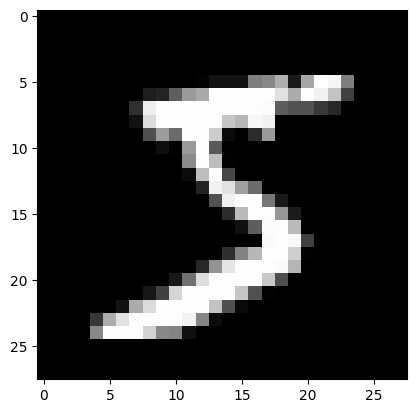

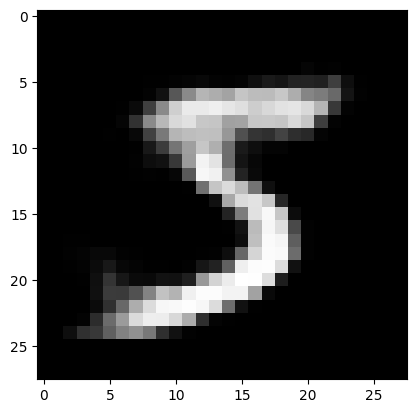

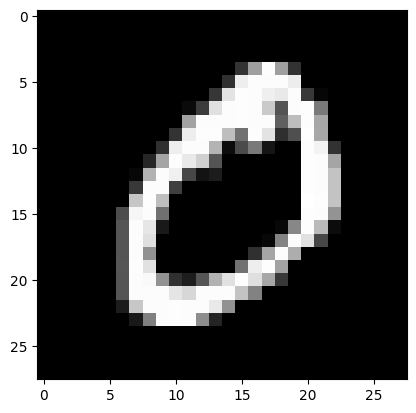

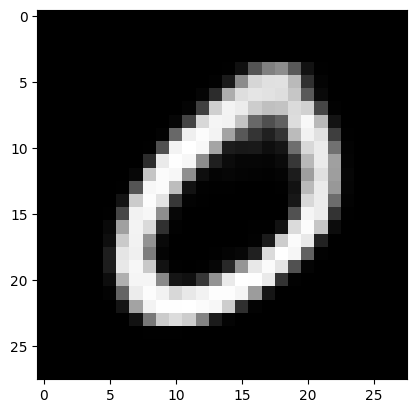

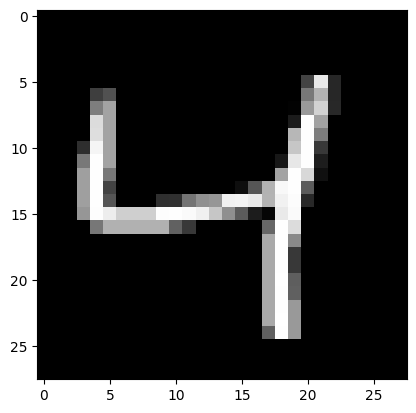

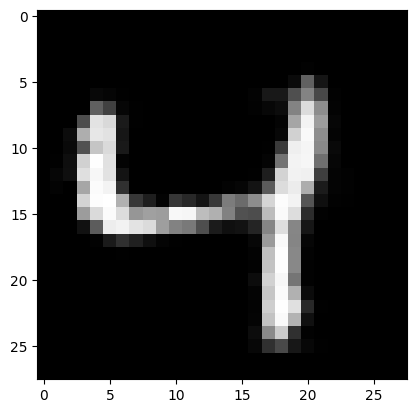

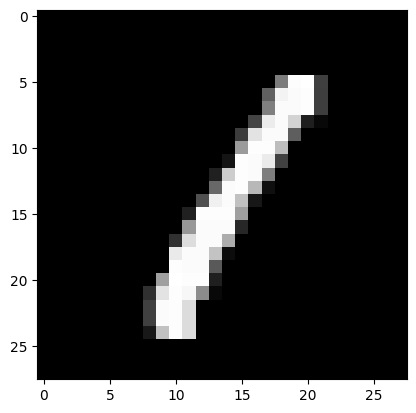

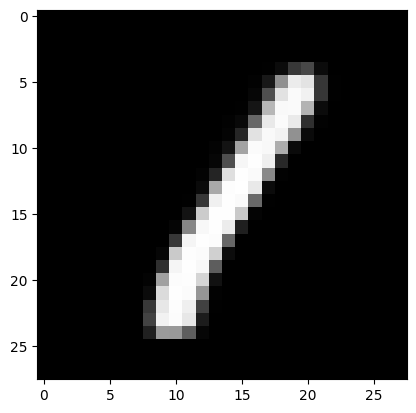

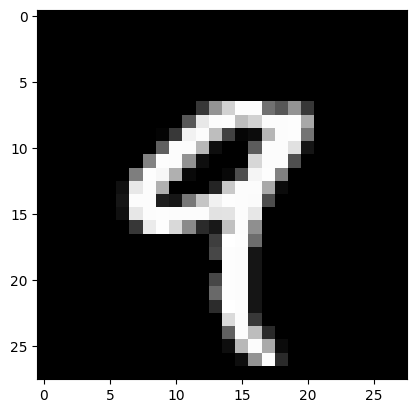

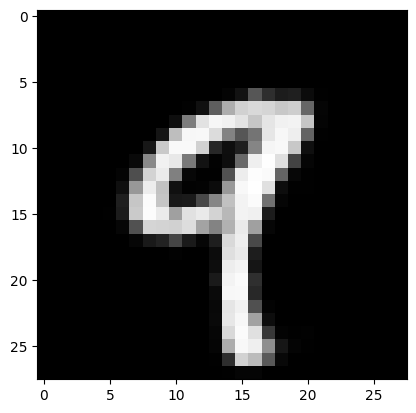

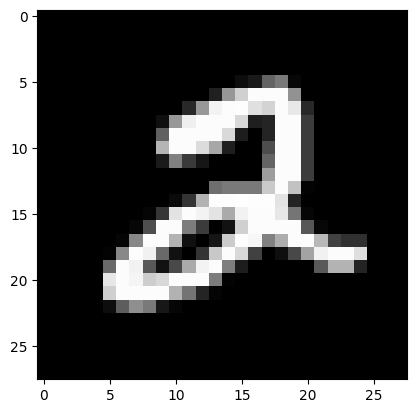

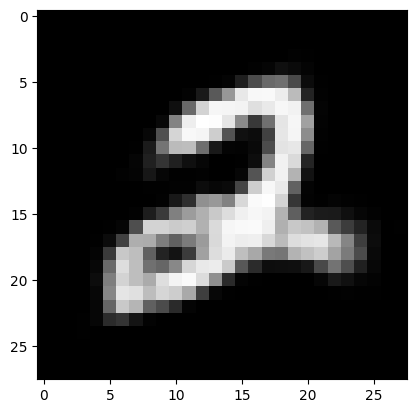

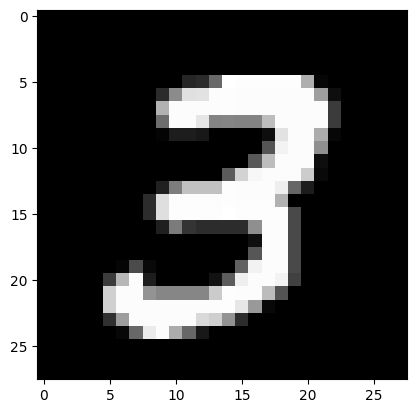

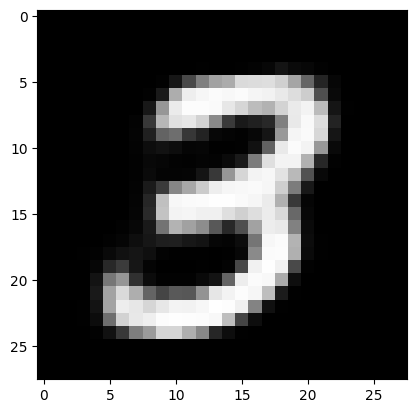

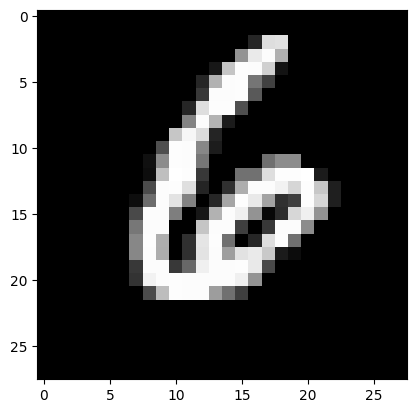

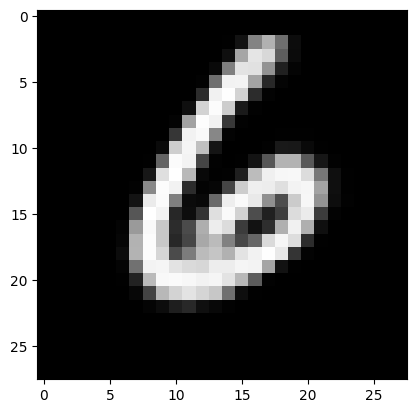

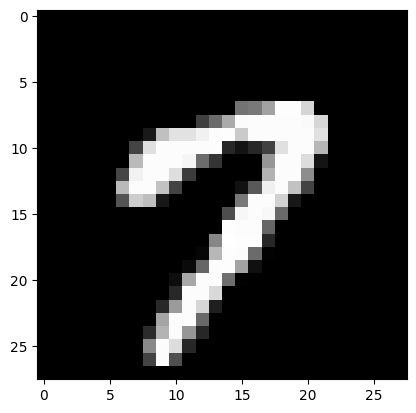

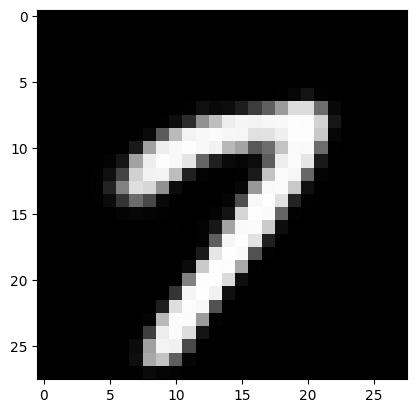

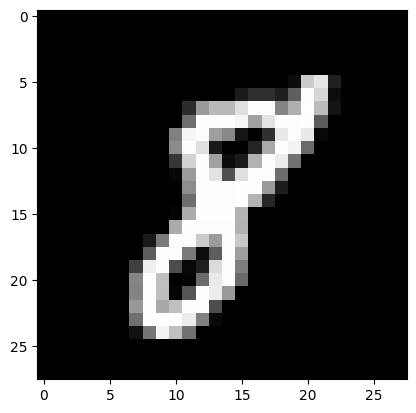

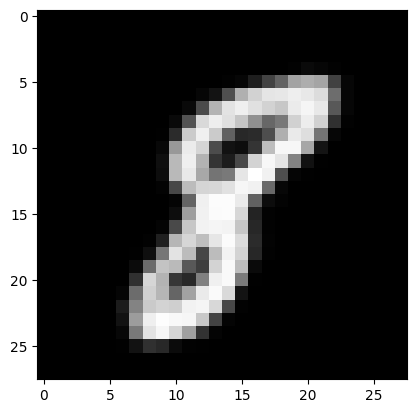

In [28]:
model.load_state_dict(torch.load("./models/" + activation_func + "model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = image_tensor.unsqueeze(0).to(device)
		reconstructed = model(image_tensor)

	reconstructed = reconstructed.squeeze(0).detach().cpu()

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [58]:
activation_func = "Convolution"
model = ConvSAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "model", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [60]:
from sklearn.cluster import KMeans

scaler = StandardScaler()
Z = scaler.fit_transform(Z)

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [61]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6798
NMI: 0.7317


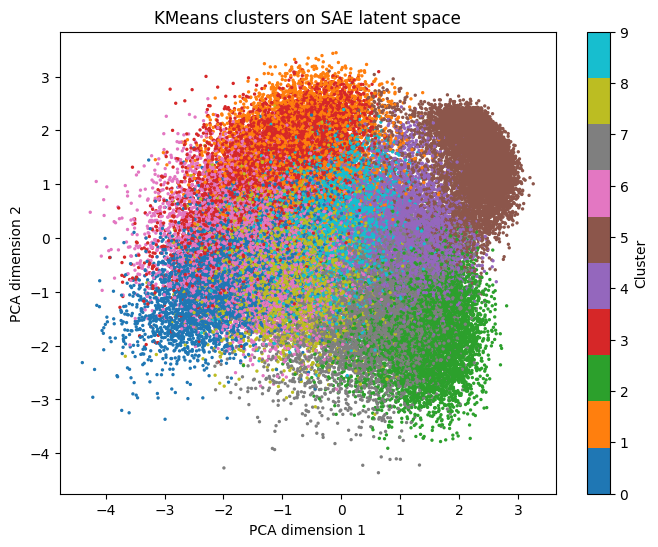

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

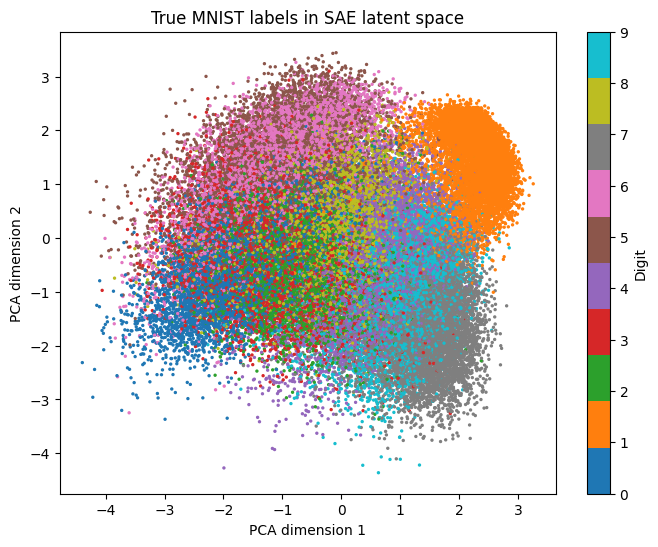

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [64]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


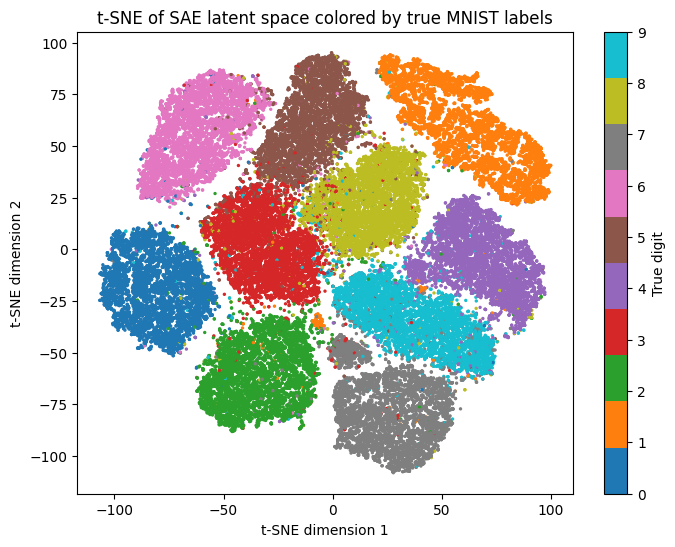

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

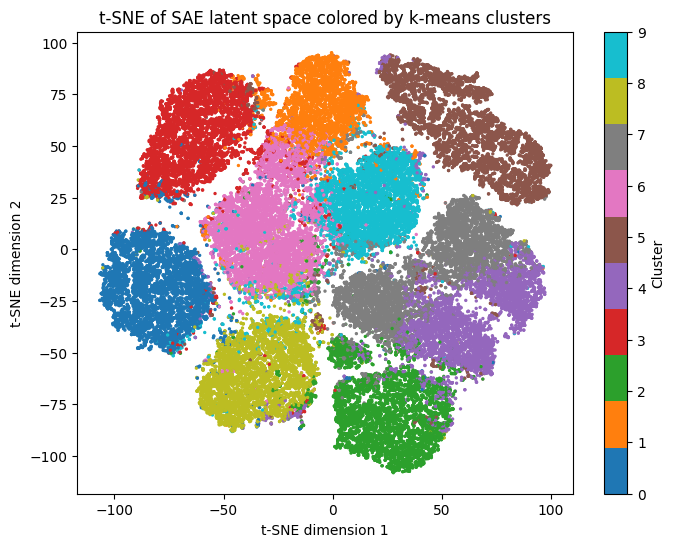

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [67]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.8036


In [38]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,3,68,6256,135,12,1,0,55,11,3
1,98,6,46,25,117,125,6296,0,35,2
2,170,17,250,498,12,120,38,21,5649,53
3,16,7707,43,46,58,26,134,68,84,64
4,4,14,23,55,4000,58,13,307,100,3108
5,102,58,106,29,2610,23,9,500,170,3359
6,7,1,45,6070,0,1955,10,3,571,123
7,6,6,3,170,1,3987,174,0,146,2
8,6496,0,123,14,12,17,202,31,45,67


In [39]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.01,0.96,0.02,0.00,0.00,0.00,0.01,0.00,0.00
1,0.01,0.00,0.01,0.00,0.02,0.02,0.93,0.00,0.01,0.00
2,0.02,0.00,0.04,0.07,0.00,0.02,0.01,0.00,0.83,0.01
3,0.00,0.93,0.01,0.01,0.01,0.00,0.02,0.01,0.01,0.01
4,0.00,0.00,0.00,0.01,0.52,0.01,0.00,0.04,0.01,0.40
5,0.01,0.01,0.02,0.00,0.37,0.00,0.00,0.07,0.02,0.48
6,0.00,0.00,0.01,0.69,0.00,0.22,0.00,0.00,0.06,0.01
7,0.00,0.00,0.00,0.04,0.00,0.89,0.04,0.00,0.03,0.00
8,0.93,0.00,0.02,0.00,0.00,0.00,0.03,0.00,0.01,0.01


## Convolutional MaxPool

### Train

In [ ]:
class ConvSAE_MaxPool(nn.Module):
    def __init__(self, latent_dim = 10):
        super().__init__()

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(1, 32, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2, stride = 2),  # 28 -> 14

            nn.Conv2d(32, 64, kernel_size = 3, padding = 1),
            nn.ReLU(),
            nn.MaxPool2d(kernel_size = 2, stride = 2),  # 14 -> 7
        )

        self.encoder_fc = nn.Linear(64 * 7 * 7, latent_dim)

        self.decoder_fc = nn.Linear(latent_dim, 64 * 7 * 7)

        self.decoder_conv = nn.Sequential(
            nn.Upsample(scale_factor = 2, mode = "nearest"),    # 7 -> 14
            nn.Conv2d(64, 32, kernel_size = 3, padding = 1),
            nn.ReLU(),

            nn.Upsample(scale_factor = 2, mode = "nearest"),    # 14 -> 28
            nn.Conv2d(32, 1, kernel_size = 3, padding = 1),
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder_conv(x)
        h = h.view(h.size(0), -1)
        z = self.encoder_fc(h)
        return z

    def decode(self, z):
        h = self.decoder_fc(z)
        h = h.view(z.size(0), 64, 7, 7)
        x_hat = self.decoder_conv(h)
        return x_hat

    def forward(self, x):
        z = self.encode(x)
        return self.decode(z)

In [41]:
activation_func = "Convolution_maxpool"
model = ConvSAE_MaxPool()
model.to(device)

pretrain_epochs = 400

loss_function = nn.BCELoss()

optimizer = optim.SGD(
    model.parameters(),
    lr = 0.1, 
    momentum = 0.9
    )

"""scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )"""

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = images.to(device)
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Train: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "model")

        print(f"Best Train Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


Train: Epoch 1/400, Loss: 0.214095
Best Train Epoch: 1/400, Loss: 0.214095
Train: Epoch 2/400, Loss: 0.138780
Best Train Epoch: 2/400, Loss: 0.138780
Train: Epoch 3/400, Loss: 0.128402
Best Train Epoch: 3/400, Loss: 0.128402
Train: Epoch 4/400, Loss: 0.123884
Best Train Epoch: 4/400, Loss: 0.123884
Train: Epoch 5/400, Loss: 0.121020
Best Train Epoch: 5/400, Loss: 0.121020
Train: Epoch 6/400, Loss: 0.119042
Best Train Epoch: 6/400, Loss: 0.119042
Train: Epoch 7/400, Loss: 0.117469
Best Train Epoch: 7/400, Loss: 0.117469
Train: Epoch 8/400, Loss: 0.116192
Best Train Epoch: 8/400, Loss: 0.116192
Train: Epoch 9/400, Loss: 0.115374
Best Train Epoch: 9/400, Loss: 0.115374
Train: Epoch 10/400, Loss: 0.114503
Best Train Epoch: 10/400, Loss: 0.114503
Train: Epoch 11/400, Loss: 0.113734
Best Train Epoch: 11/400, Loss: 0.113734
Train: Epoch 12/400, Loss: 0.113236
Best Train Epoch: 12/400, Loss: 0.113236
Train: Epoch 13/400, Loss: 0.112574
Best Train Epoch: 13/400, Loss: 0.112574
Train: Epoch 14/4

### Visualize

In [42]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = ConvSAE_MaxPool()
model.to(device)

ConvSAE_MaxPool(
  (encoder_conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (encoder_fc): Linear(in_features=3136, out_features=10, bias=True)
  (decoder_fc): Linear(in_features=10, out_features=3136, bias=True)
  (decoder_conv): Sequential(
    (0): Upsample(scale_factor=2.0, mode='nearest')
    (1): Conv2d(64, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (2): ReLU()
    (3): Upsample(scale_factor=2.0, mode='nearest')
    (4): Conv2d(32, 1, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (5): Sigmoid()
  )
)

#### Finetuned

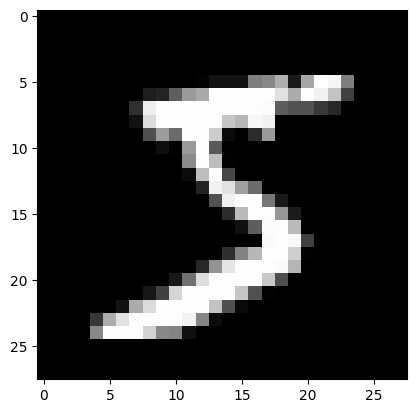

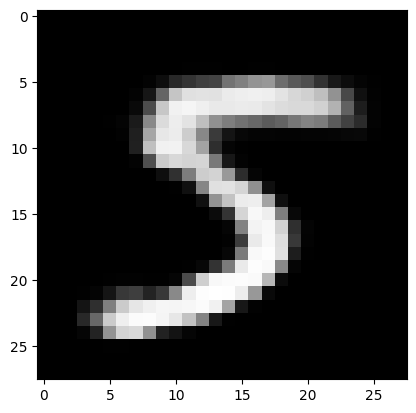

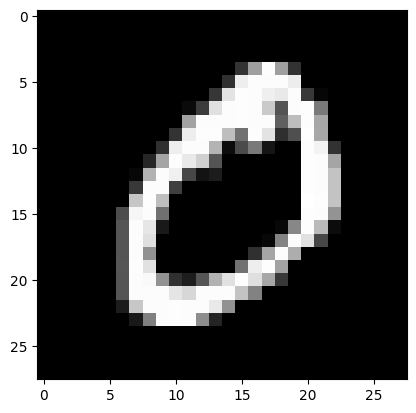

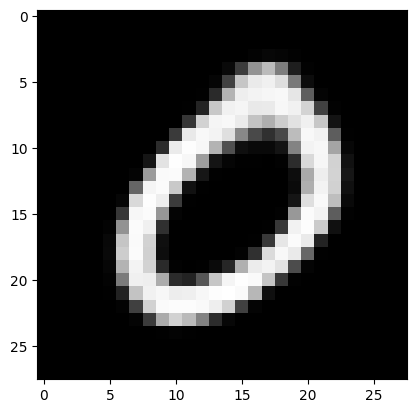

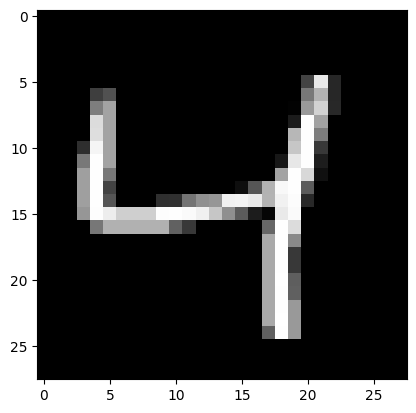

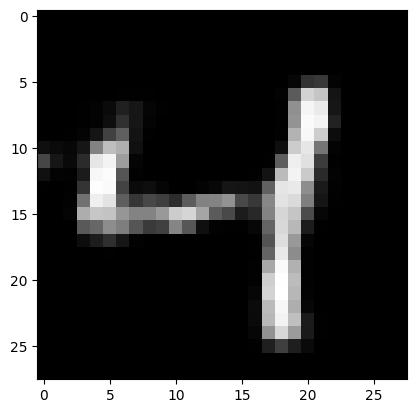

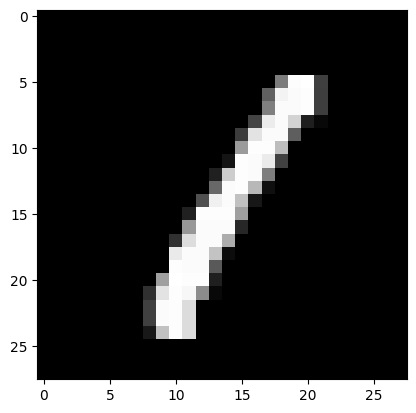

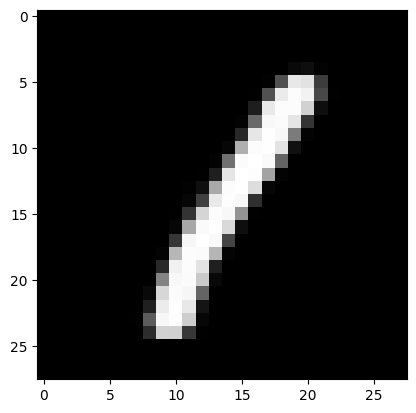

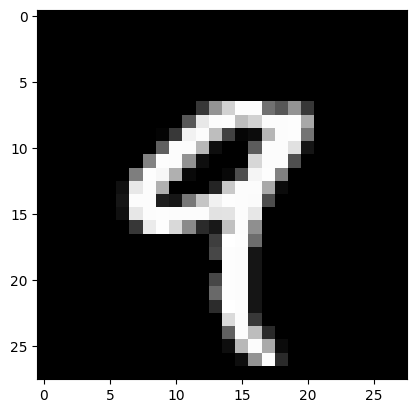

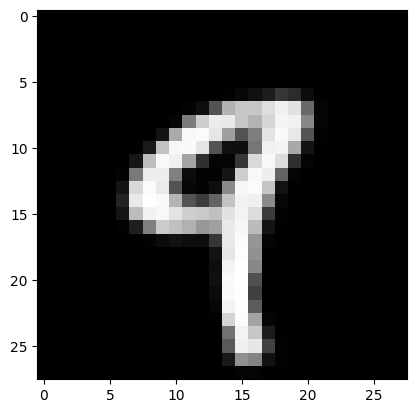

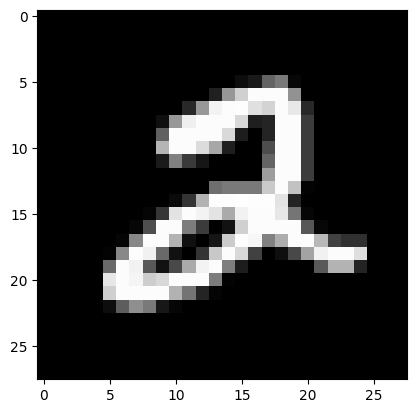

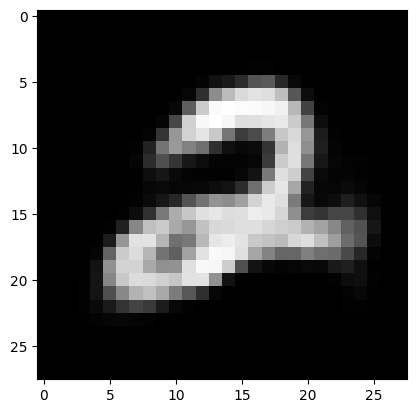

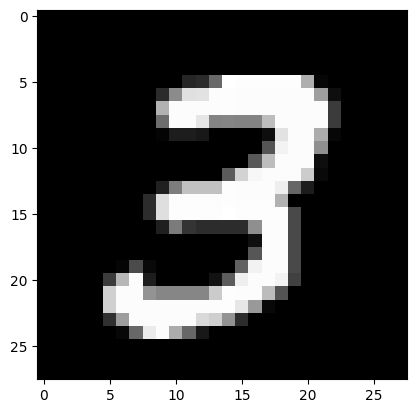

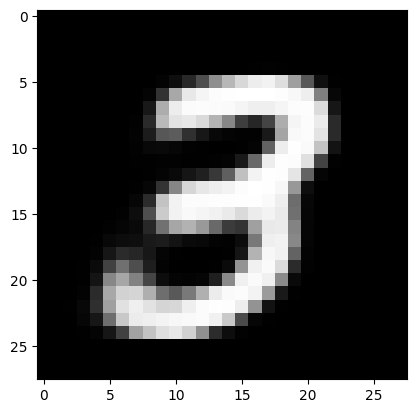

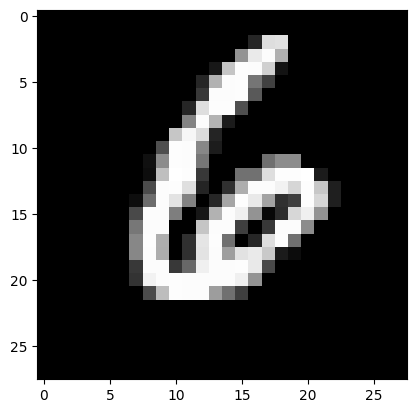

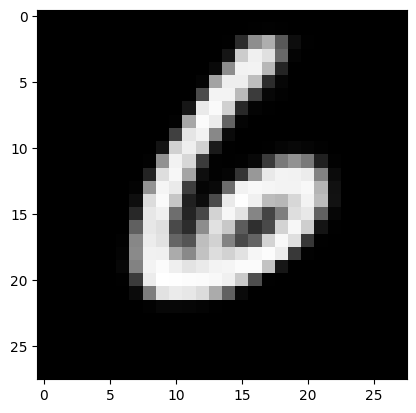

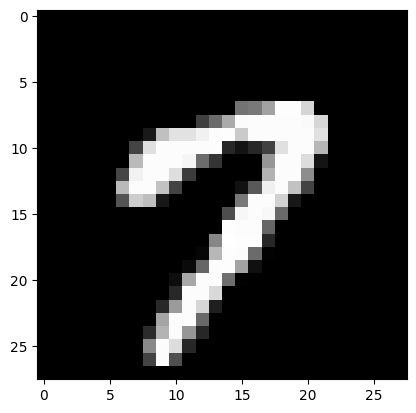

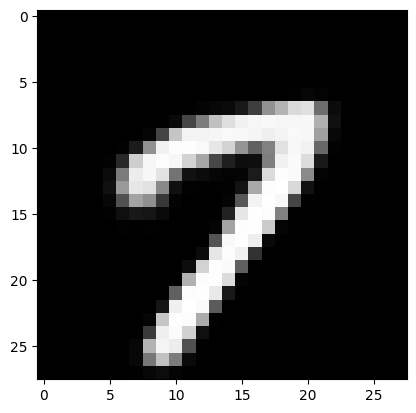

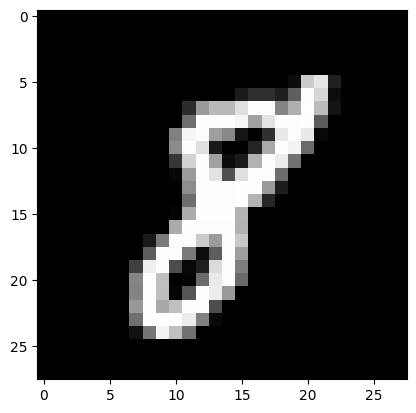

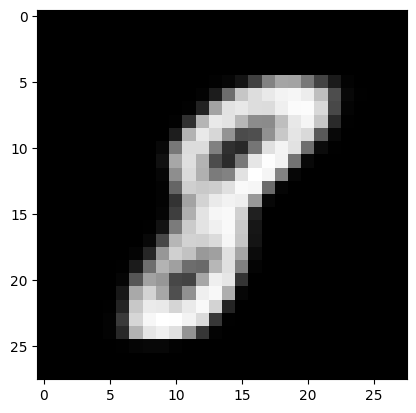

In [43]:
model.load_state_dict(torch.load("./models/" + activation_func + "model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = image_tensor.unsqueeze(0).to(device)
		reconstructed = model(image_tensor)

	reconstructed = reconstructed.squeeze(0).detach().cpu()

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [80]:
activation_func = "Convolution_maxpool"
model = ConvSAE_MaxPool()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "model", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [81]:
from sklearn.cluster import KMeans
from sklearn.cluster import KMeans

scaler = StandardScaler()
Z = scaler.fit_transform(Z)

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [82]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6007
NMI: 0.6774


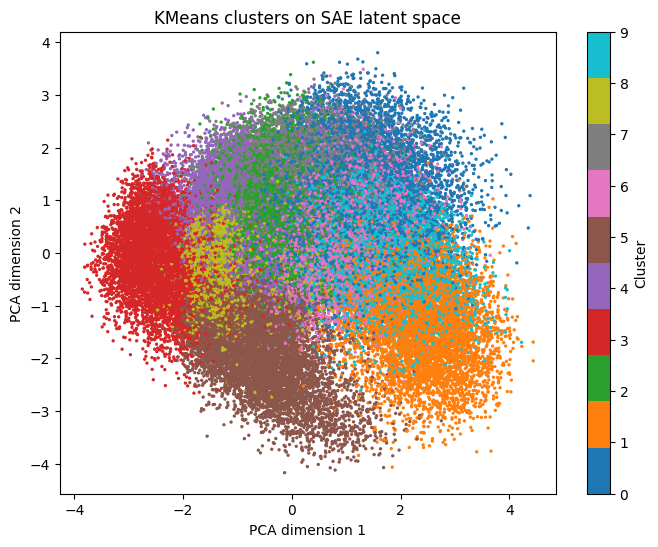

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

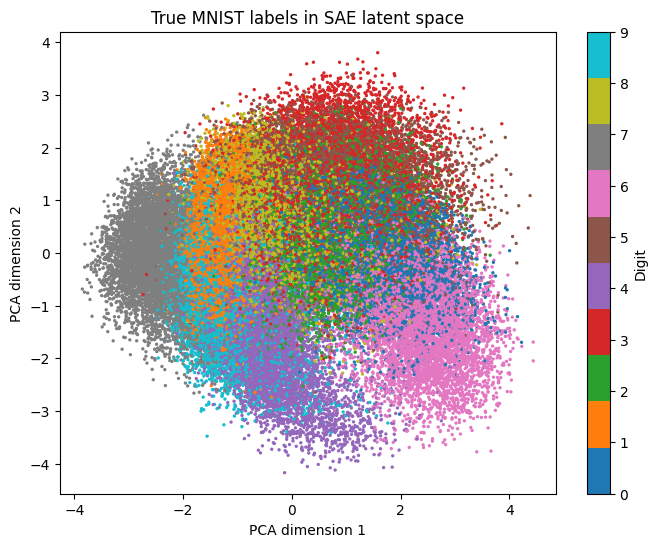

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [85]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


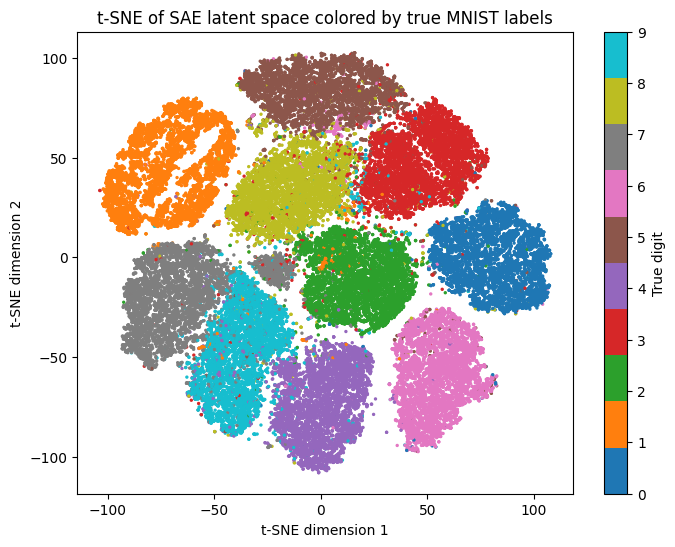

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

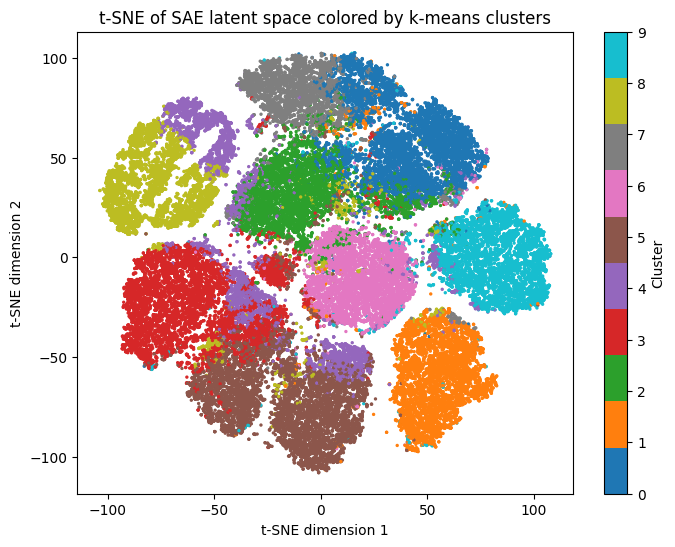

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [88]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.7410


In [89]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,29,2,19,5657,0,2045,25,1,563,82
1,38,17,62,13,60,185,6423,0,47,6
2,64,24,367,843,2,150,23,10,4859,92
3,1,2,107,131,38,17,0,6514,105,1852
4,249,2161,125,110,1214,33,36,391,674,1175
5,24,5,92,47,5367,36,16,260,164,3471
6,5,37,6021,106,25,1,1,35,11,9
7,3,4,6,119,2,3778,175,0,183,4
8,39,5625,68,83,109,35,133,59,170,213


In [90]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.00,0.67,0.00,0.24,0.00,0.00,0.07,0.01
1,0.01,0.00,0.01,0.00,0.01,0.03,0.94,0.00,0.01,0.00
2,0.01,0.00,0.06,0.13,0.00,0.02,0.00,0.00,0.76,0.01
3,0.00,0.00,0.01,0.01,0.00,0.00,0.00,0.74,0.01,0.21
4,0.04,0.35,0.02,0.02,0.20,0.01,0.01,0.06,0.11,0.19
5,0.00,0.00,0.01,0.00,0.57,0.00,0.00,0.03,0.02,0.37
6,0.00,0.01,0.96,0.02,0.00,0.00,0.00,0.01,0.00,0.00
7,0.00,0.00,0.00,0.03,0.00,0.88,0.04,0.00,0.04,0.00
8,0.01,0.86,0.01,0.01,0.02,0.01,0.02,0.01,0.03,0.03


## Convolutional No MaxPol - Normalized

### Train

In [ ]:
import torch
import torch.nn as nn

class ConvSAE(nn.Module):
    def __init__(self, latent_dim = 10):
        super().__init__()

        self.encoder_conv = nn.Sequential(
            nn.Conv2d(
                1, 32, 
                kernel_size = 3, 
                stride = 2, 
                padding = 1
                ),  # 28 -> 14
            nn.ReLU(),

            nn.Conv2d(
                32, 64, 
                kernel_size = 3, 
                stride = 2, 
                padding = 1
                ), # 14 -> 7
            nn.ReLU(),
        )

        self.encoder_fc = nn.Linear(64 * 7 * 7, latent_dim)

        self.decoder_fc = nn.Linear(latent_dim, 64 * 7 * 7)

        self.decoder_conv = nn.Sequential(
            nn.ConvTranspose2d(
                64, 32,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),  # 7 -> 14
            nn.ReLU(),

            nn.ConvTranspose2d(
                32, 1,
                kernel_size = 3,
                stride = 2,
                padding = 1,
                output_padding = 1
            ),  # 14 -> 28
            nn.Sigmoid()
        )

    def encode(self, x):
        h = self.encoder_conv(x)
        h = h.view(h.size(0), -1)
        z = self.encoder_fc(h)
        return z

    def decode(self, z):
        h = self.decoder_fc(z)
        h = h.view(z.size(0), 64, 7, 7)
        x_hat = self.decoder_conv(h)
        return x_hat

    def forward(self, x):
        z = self.encode(x)
        x_hat = self.decode(z)
        return x_hat

In [ ]:
activation_func = "Convolution_Normalized"
model = ConvSAE()
model.to(device)

pretrain_epochs = 400

loss_function = nn.BCELoss()

optimizer = optim.AdamW(
	model.parameters(),
	lr = 1e-3,
	weight_decay = 1e-4
	)

"""scheduler = optim.lr_scheduler.StepLR(
    optimizer, 
    step_size = 20000, #Amount of iterations the scheduler will update the lr
    gamma = 0.1 #by how much the scheduler will divide the current lr
    )"""

best_loss = (float("inf"), 0)

model.train()
for epoch in range(pretrain_epochs):
    batch_losses = []
    
    for images, _ in dataloader:

        images = images.to(device)
        reconstructed = model(images)
        loss = loss_function(reconstructed, images)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        #scheduler.step()

        batch_losses.append(loss.item())
    
    epoch_loss = sum(batch_losses) / len(batch_losses)

    print(f"Train: Epoch {epoch+1}/{pretrain_epochs}, Loss: {epoch_loss:.6f}")

    if epoch_loss <= best_loss[0]:
        best_loss = (epoch_loss, epoch + 1)
        torch.save(model.state_dict(), "./models/" + activation_func + "model")

        print(f"Best Train Epoch: {best_loss[1]}/{pretrain_epochs}, Loss: {best_loss[0]:.6f}")


Train: Epoch 1/400, Loss: 0.224420
Best Train Epoch: 1/400, Loss: 0.224420
Train: Epoch 2/400, Loss: 0.142924
Best Train Epoch: 2/400, Loss: 0.142924
Train: Epoch 3/400, Loss: 0.131373
Best Train Epoch: 3/400, Loss: 0.131373
Train: Epoch 4/400, Loss: 0.124881
Best Train Epoch: 4/400, Loss: 0.124881
Train: Epoch 5/400, Loss: 0.120816
Best Train Epoch: 5/400, Loss: 0.120816
Train: Epoch 6/400, Loss: 0.118139
Best Train Epoch: 6/400, Loss: 0.118139
Train: Epoch 7/400, Loss: 0.116190
Best Train Epoch: 7/400, Loss: 0.116190
Train: Epoch 8/400, Loss: 0.114691
Best Train Epoch: 8/400, Loss: 0.114691
Train: Epoch 9/400, Loss: 0.113481
Best Train Epoch: 9/400, Loss: 0.113481
Train: Epoch 10/400, Loss: 0.112528
Best Train Epoch: 10/400, Loss: 0.112528
Train: Epoch 11/400, Loss: 0.111624
Best Train Epoch: 11/400, Loss: 0.111624
Train: Epoch 12/400, Loss: 0.110877
Best Train Epoch: 12/400, Loss: 0.110877
Train: Epoch 13/400, Loss: 0.110226
Best Train Epoch: 13/400, Loss: 0.110226
Train: Epoch 14/4

### Visualize

In [ ]:
examples = {}

for image, label in dataset:
    label = int(label)
    if label not in examples:
        examples[label] = image

    if len(examples) == 10:
        break
    
model = ConvSAE()
model.to(device)

ConvSAE(
  (encoder_conv): Sequential(
    (0): Conv2d(1, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (1): ReLU()
    (2): Conv2d(32, 64, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1))
    (3): ReLU()
  )
  (encoder_fc): Linear(in_features=3136, out_features=10, bias=True)
  (decoder_fc): Linear(in_features=10, out_features=3136, bias=True)
  (decoder_conv): Sequential(
    (0): ConvTranspose2d(64, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (1): ReLU()
    (2): ConvTranspose2d(32, 1, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), output_padding=(1, 1))
    (3): Sigmoid()
  )
)

#### Finetuned

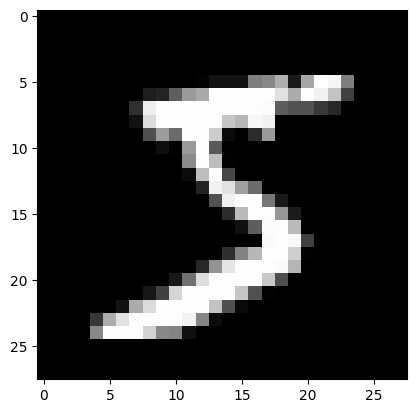

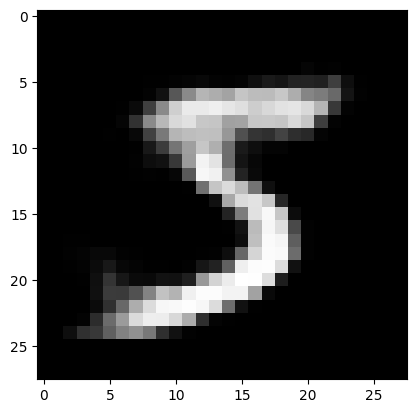

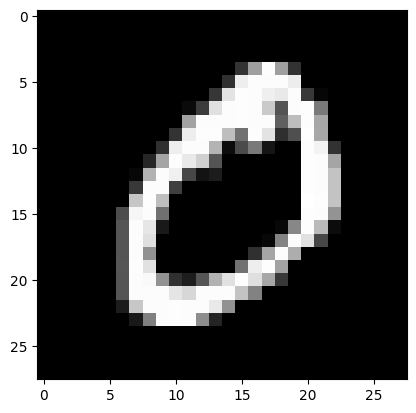

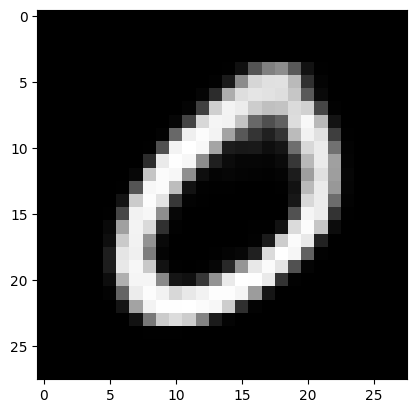

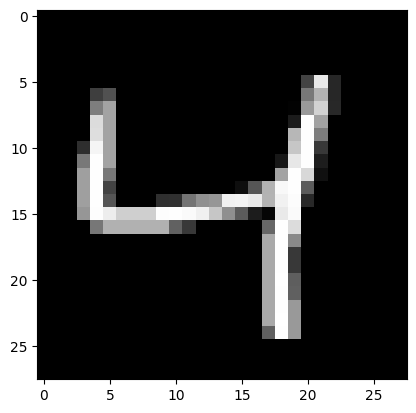

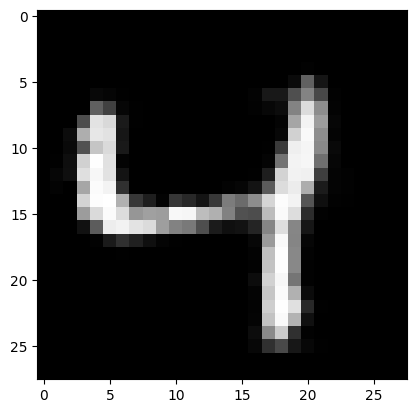

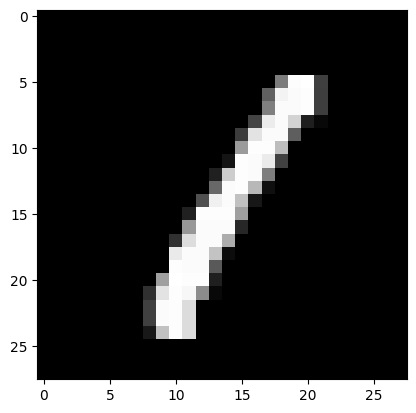

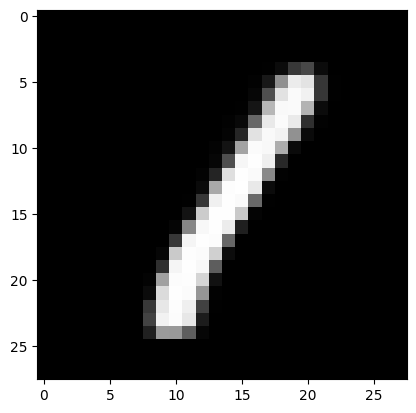

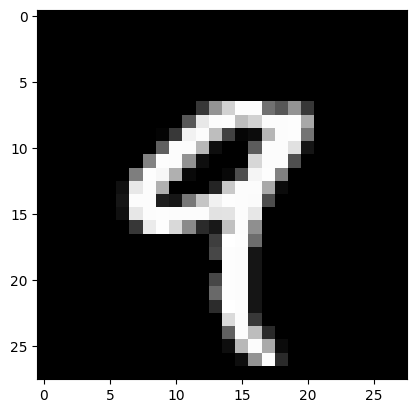

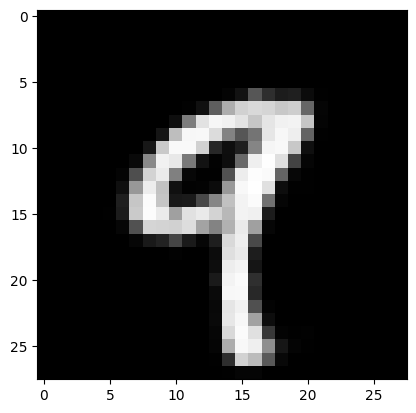

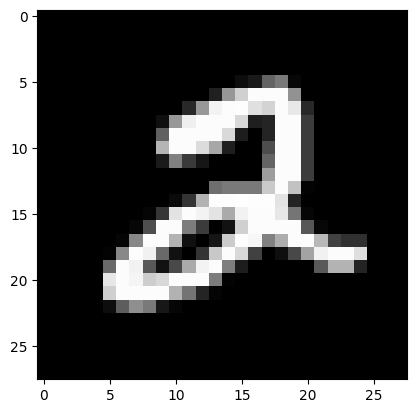

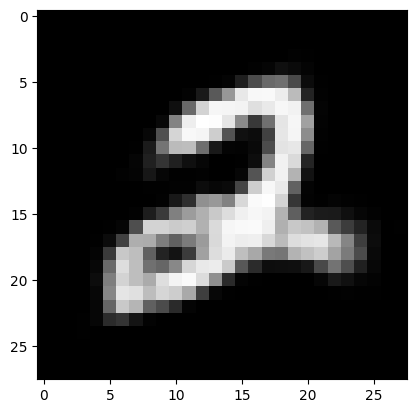

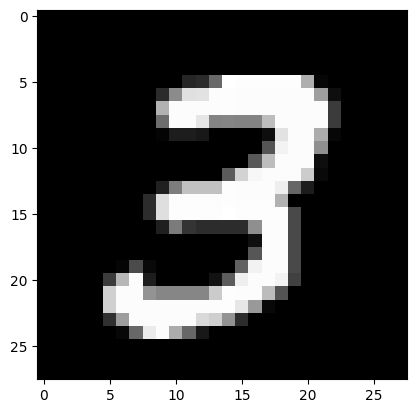

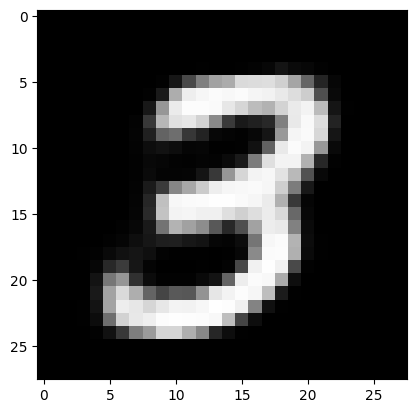

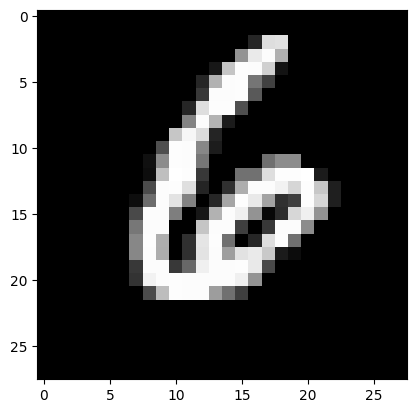

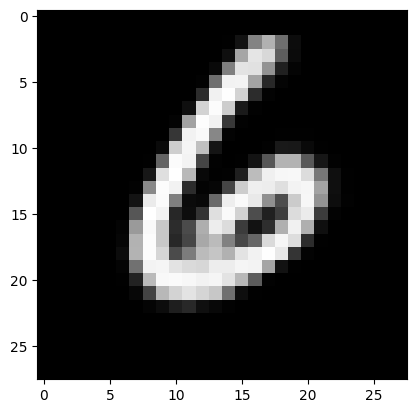

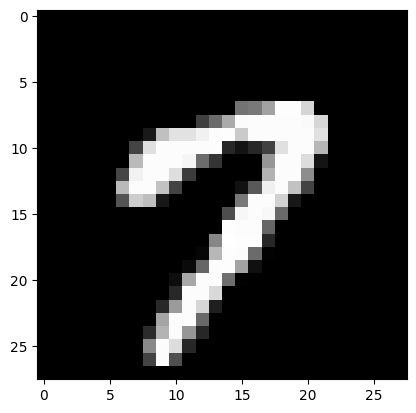

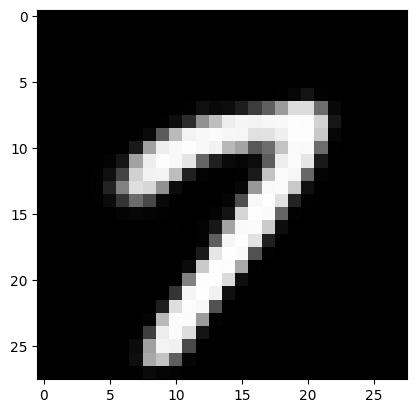

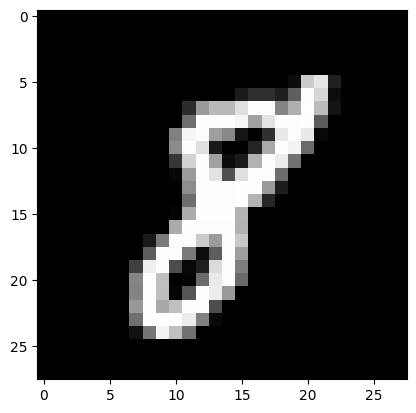

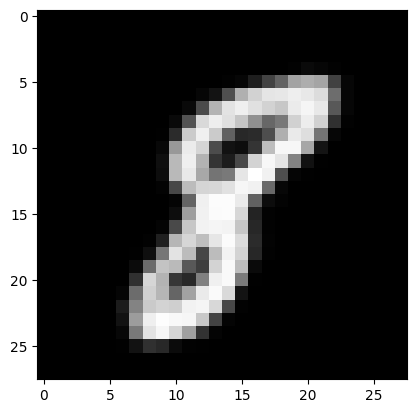

In [ ]:
model.load_state_dict(torch.load("./models/" + activation_func + "model", weights_only = True))
model.eval()

for digit in examples:

	image_tensor = examples[digit]
	image = tensor_to_img(image_tensor)
	imgplot = plt.imshow(image, cmap = "gray")
	plt.show()

	with torch.no_grad():
		image_tensor = image_tensor.unsqueeze(0).to(device)
		reconstructed = model(image_tensor)

	reconstructed = reconstructed.squeeze(0).detach().cpu()

	image_reconstructed = tensor_to_img(reconstructed)

	imgplot = plt.imshow(image_reconstructed, cmap = "gray")
	plt.show()

### Clustering

In [68]:
activation_func = "Convolution"
model = ConvSAE()
model.to(device)

model.load_state_dict(
    torch.load("./models/" + activation_func + "model", weights_only = True)
)

model.eval()

all_z = []
all_labels = []

model.eval()

with torch.no_grad():
    for images, labels in dataloader:
        images = images.to(device)

        z = model.encode(images)

        all_z.append(z.cpu().numpy())
        all_labels.append(labels.numpy())

Z = np.concatenate(all_z, axis = 0)
y_true = np.concatenate(all_labels, axis = 0)

print(Z.shape)
print(y_true.shape)

(70000, 10)
(70000,)


In [69]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import normalize

Z = normalize(Z)

n_clusters = 10

kmeans = KMeans(
    n_clusters = n_clusters,
    n_init = 20,
    random_state = 42
)

cluster_labels = kmeans.fit_predict(Z)

centroids = kmeans.cluster_centers_

print(cluster_labels.shape)
print(centroids.shape)

(70000,)
(10, 10)


In [70]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

ari = adjusted_rand_score(y_true, cluster_labels)
nmi = normalized_mutual_info_score(y_true, cluster_labels)

print(f"ARI: {ari:.4f}")
print(f"NMI: {nmi:.4f}")

ARI: 0.6719
NMI: 0.7251


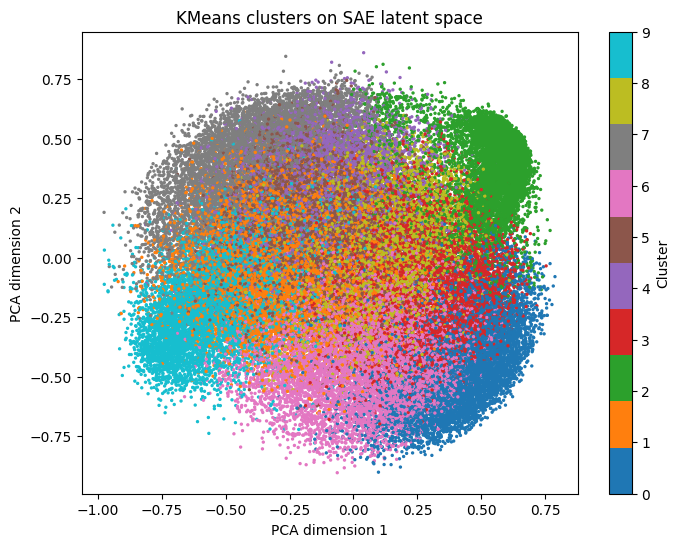

In [ ]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components = 2, random_state = 42)
Z_2d = pca.fit_transform(Z)

plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("KMeans clusters on SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

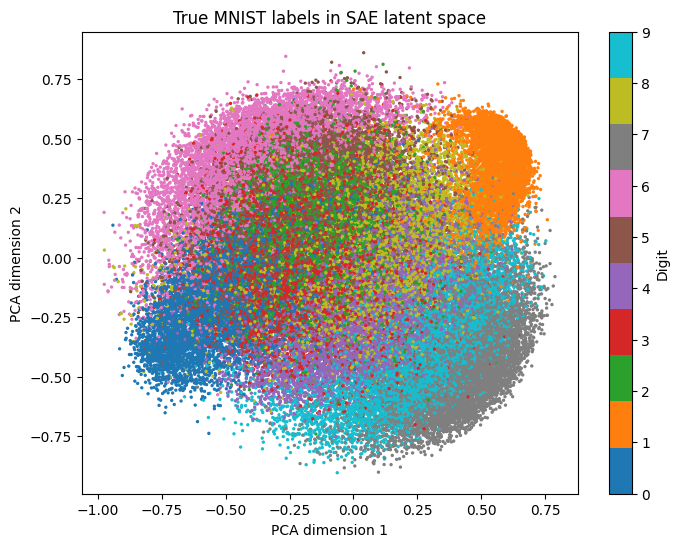

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_2d[:, 0],
    Z_2d[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("True MNIST labels in SAE latent space")
plt.xlabel("PCA dimension 1")
plt.ylabel("PCA dimension 2")
plt.colorbar(label = "Digit")
plt.show()

In [73]:
from sklearn.manifold import TSNE
import matplotlib.pyplot as plt
import numpy as np

tsne = TSNE(
    n_components = 2,
    perplexity = 30,
    learning_rate = "auto",
    init = "pca",
    random_state = 42
)

Z_tsne = tsne.fit_transform(Z)

print(Z_tsne.shape)

(70000, 2)


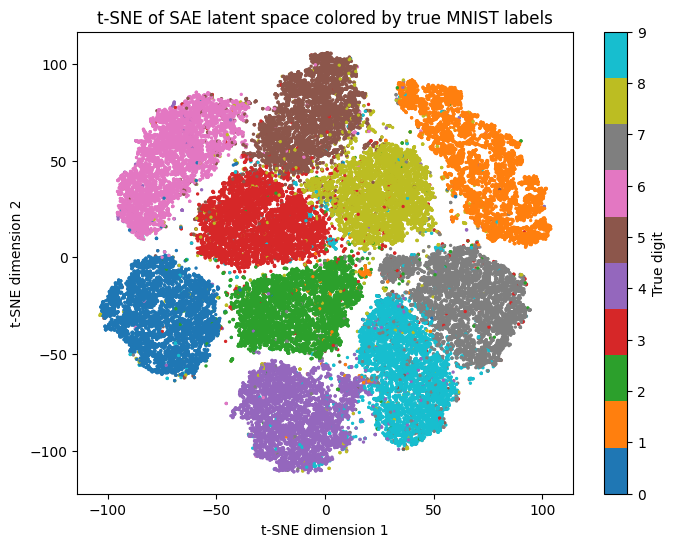

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = y_true,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by true MNIST labels")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "True digit")
plt.show()

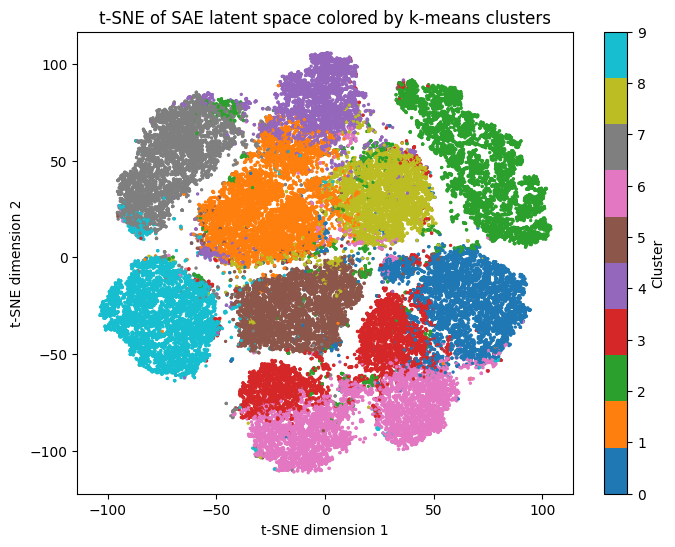

In [ ]:
plt.figure(figsize = (8, 6))
plt.scatter(
    Z_tsne[:, 0],
    Z_tsne[:, 1],
    c = cluster_labels,
    s = 2,
    cmap = "tab10"
)
plt.title("t-SNE of SAE latent space colored by k-means clusters")
plt.xlabel("t-SNE dimension 1")
plt.ylabel("t-SNE dimension 2")
plt.colorbar(label = "Cluster")
plt.show()

In [76]:
from scipy.optimize import linear_sum_assignment
from sklearn.metrics import confusion_matrix
import numpy as np

def clustering_accuracy(y_true, y_pred):
    cm = confusion_matrix(y_true, y_pred)
    row_ind, col_ind = linear_sum_assignment(-cm)
    return cm[row_ind, col_ind].sum() / y_true.size

acc = clustering_accuracy(y_true, cluster_labels)

print(f"Clustering Accuracy: {acc:.4f}")

Clustering Accuracy: 0.7958


In [77]:
import pandas as pd

cluster_digit_counts = pd.crosstab(
    pd.Series(cluster_labels, name = "Cluster"),
    pd.Series(y_true, name = "True digit")
)

cluster_digit_counts

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,4,2,121,155,2,3,0,6404,41,355
1,9,1,46,6093,0,1689,7,3,673,126
2,61,7758,86,112,104,52,225,91,339,127
3,54,34,73,15,2475,20,7,393,166,2878
4,11,5,4,253,3,4279,199,0,222,5
5,1,59,6274,159,15,1,2,50,20,3
6,15,11,29,62,4100,68,12,318,184,3374
7,67,3,44,24,109,128,6199,0,44,1
8,31,4,179,251,4,54,11,5,5069,21


In [78]:
cluster_digit_percentages = cluster_digit_counts.div(
    cluster_digit_counts.sum(axis = 1),
    axis = 0
)

cluster_digit_percentages.round(2)

True digit,0,1,2,3,4,5,6,7,8,9
Cluster,,,,,,,,,,
0,0.00,0.00,0.02,0.02,0.00,0.00,0.00,0.90,0.01,0.05
1,0.00,0.00,0.01,0.70,0.00,0.20,0.00,0.00,0.08,0.01
2,0.01,0.87,0.01,0.01,0.01,0.01,0.03,0.01,0.04,0.01
3,0.01,0.01,0.01,0.00,0.40,0.00,0.00,0.06,0.03,0.47
4,0.00,0.00,0.00,0.05,0.00,0.86,0.04,0.00,0.04,0.00
5,0.00,0.01,0.95,0.02,0.00,0.00,0.00,0.01,0.00,0.00
6,0.00,0.00,0.00,0.01,0.50,0.01,0.00,0.04,0.02,0.41
7,0.01,0.00,0.01,0.00,0.02,0.02,0.94,0.00,0.01,0.00
8,0.01,0.00,0.03,0.04,0.00,0.01,0.00,0.00,0.90,0.00
